# Encoder swap: does hallucination come from the encoder or from the language model?

**Question (task document).** Replace LLaVA's CLIP-style encoder with a JEPA encoder (trained without a generative or contrastive-language objective), re-run the diagnostics, and ask whether the hallucination-relevant computation looks qualitatively different. If it does, hallucination is at least partly *encoder-driven*; if not, it is more likely a *language-model binding failure*.

**Design.** Both models share the Vicuna-7B-v1.5 architecture, the same Yes/No token ids, the same POPE questions (same ids, same seeds) and the same measurement code (one `Engine` class). Only the encoder side differs (LLaVA: CLIP ViT-L/14-336 + its fine-tuned projector and LM; JEPA-VLM: I-JEPA ViT-H/16 + a projector we trained + frozen Vicuna). Two separate questions are answered:

1. **Mechanism.** Is the computation that turns evidence into a Yes/No answer the same? (direct logit attribution, mean-ablation of the *same* component sets with random controls, patching of last-position activations and of K/V of image vs text tokens)
2. **Information.** How much object information reaches the language model, and does the model use it? (linear probes on the last-position residual stream vs the model's own answer)

**Pre-registered criteria (fixed before the LLaVA runs; evaluated automatically in the last cell).**

| id | criterion |
|---|---|
| M1 | the most necessary MLP window agrees (or Spearman over 8 windows $\ge 0.6$) |
| M2 | the JEPA-derived evidence MLPs hurt LLaVA more than random MLP sets ($z\le -2$ or below every random set) |
| M3 | in layers 8-15, patching text-token K/V reproduces more of the corruption effect than image-token K/V (CI of the difference excludes 0) in both models |
| M4 | direct-effect truth parts correlate (noise-ceiling-corrected Spearman $\ge 0.6$) and the L20/L28 constants have the same sign |
| M5 | evidence and opposing MLP sums are anti-correlated within class ($r\le -0.3$) in both |
| I1 | JEPA's probe ceiling is lower than LLaVA's (CI excludes 0) |
| I2 | both models leave decodable information unused (ceiling − output AUROC $> 0.02$) |
| I3 | the probe recovers a larger share of JEPA's errors than of LLaVA's |
| I4 | LLaVA separates the classes better than JEPA |

Mechanism verdict: SAME if at most one of M1-M5 fails, DIFFERENT if at most one passes, otherwise PARTLY. Information verdict: I1 true $\Rightarrow$ the encoder/projector delivers less usable information (encoder-driven component); I1 false and I2 true $\Rightarrow$ language-model-side.

**Datasets to attach.**
- yours: `dla-jepa-vicuna-noise` (your step 4-7 result files; used for comparison and for the old-vs-new engine check), `jepa-projector-fixed-ckpts` (`best.pt`), `vlm-questions` (your copy of `all_questions.json`), COCO val2014 (`nadaibrahim/coco2014`); after a crash also `encoder-swap-compare` (this notebook's own outputs).
- Rohan's (`nocturnalnerd18`): `dla-llava` (cross-check and 3000-question LLaVA numbers); optional `atp-llava-noising` (Fig 8).

**Runtime (2 x T4).** Part B (LLaVA) about 2-3 h, Part C (JEPA) about 20 min, Part D (analysis) about 10 min. Every long loop checkpoints and pushes to the `encoder-swap-compare` dataset. Set `RUN_LLAVA` / `RUN_JEPA` to False to run only the analysis on saved outputs.

In [1]:
!pip install -q transformers==5.16.1 accelerate==1.14.0 bitsandbytes==0.50.2 pillow==12.3.0 sentencepiece scikit-learn scipy 2>&1 | tail -2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 51.4 MB/s eta 0:00:00


In [2]:
# 1. CONFIG
import os, re, json, glob, math, time, random, shutil, subprocess, hashlib, gc, warnings
from collections import Counter
import numpy as np, pandas as pd
warnings.filterwarnings("ignore", category=UserWarning)

USERNAME     = "ponishbhatia"                  # the Kaggle account you RUN this notebook from: the checkpoint dataset is pushed to <USERNAME>/encoder-swap-compare (must match the KAGGLE_USERNAME secret)
DATA_OWNER   = "ponishbhatia2"                 # the Kaggle account that OWNS your input datasets (vlm-questions, jepa-projector-fixed-ckpts, dla-jepa-vicuna-noise)
ROHAN        = "nocturnalnerd18"               # Rohan's Kaggle user (dla-llava etc.)
INPUT_ROOT   = os.environ.get("ES_INPUT", "/kaggle/input")
OUT_DIR      = os.environ.get("ES_OUT", "/kaggle/working/encoder_swap")
DATASET_SLUG = "encoder-swap-compare"          # outputs of this notebook are pushed here (attach it as an input after a crash to resume)
UPLOAD       = True                            # push checkpoints/results to Kaggle (needs KAGGLE_USERNAME / KAGGLE_KEY in Kaggle secrets)
SOFT_FAIL    = True                            # True: a failing cell prints its traceback and the notebook carries on
SEED         = 0

RUN_LLAVA    = True                            # Part B: LLaVA-1.5 runs (clean pass, ablations, patching)   ~2-3 h on 2xT4
RUN_JEPA     = True                            # Part C: JEPA-VLM clean pass (+ equivalence check against your old results)   ~20 min
VALIDATE_JEPA_N = 40                           # questions on which the new engine re-computes your step 6/7 numbers (0 = skip)

# questions (identical selection procedure to the JEPA runs: same file, same seeds => same question ids)
N_EVAL_FULL  = 1000                            # size of the balanced evaluation list (as in the JEPA notebook)
N_CMP        = 1000                            # questions for the clean pass (DLA, hidden states, behaviour)
N_ABL        = 400                             # step-6 style ablations (the first 400 = the ones used for JEPA)
N_PATCH      = 300                             # step-7 style patching (the first 300 = the ones used for JEPA)
N_MEAN       = 200                             # reference questions for mean activations
N_RANDOM     = 10                              # random control sets per group (as in the JEPA runs)

# models
LLAVA_NAME   = "llava-hf/llava-1.5-7b-hf"
LLAVA_K      = None                            # None = calibrate on 120 questions so the corrupted AUROC is ~0.5; or set a number
JEPA_K       = 0.5                             # the noise multiplier used for the JEPA results
CKPT_DIR     = f"/kaggle/input/datasets/{DATA_OWNER}/jepa-projector-fixed-ckpts"
CKPT_NAME    = "best.pt"
LLM_PATH     = "lmsys/vicuna-7b-v1.5"
VIT_ID       = "facebook/ijepa_vith16_1k"
PROMPT_JEPA  = "A chat between a curious human and an artificial intelligence assistant. USER: {q} Answer with Yes or No. ASSISTANT:"
IMG_DIR      = "/kaggle/input/datasets/nadaibrahim/coco2014/val2014/val2014"                      # POPE images
AMBER_IMAGE_DIR = f"/kaggle/input/datasets/{ROHAN}/amber-hallucination/image"                      # only for HALLUC_TYPE = "attribute" / "relation"
VG_IMAGE_DIRS = ["/kaggle/temp", "/kaggle/temp/VG_100K_2"]                                          # only for relation/reefknot: download Visual Genome first (see Rohan's collect notebook)
HALLUC_TYPE  = "object"                        # "object" = POPE (the full comparison with your earlier JEPA results). "attribute"/"relation" run the same pipeline on the other types (untested; the old-artifact cells are skipped).
QUESTIONS_JSON = f"/kaggle/input/datasets/{DATA_OWNER}/vlm-questions/all_questions.json"

YES_ID, NO_ID = 3869, 1939
EVID_MLPS = ["L16.mlp", "L17.mlp", "L18.mlp", "L20.mlp", "L23.mlp"]
OPP_MLPS  = ["L21.mlp", "L24.mlp", "L27.mlp"]
BRAKE     = ["L28.mlp", "L30.mlp"]
BIAS_HEADS = ["L26H3", "L17H16", "L26H27", "L24H8", "L19H10"]
EVID_HEADS = ["L16H0", "L16H18", "L21H14", "L27H7"]
WINDOWS7  = [(0, 7), (8, 15), (16, 19), (20, 23), (24, 27), (28, 31)]

os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(f"{OUT_DIR}/figs", exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
print("output dir:", OUT_DIR)

output dir: /kaggle/working/encoder_swap


In [3]:
# 2. HELPERS: file discovery, questions, statistics, checkpoints, Kaggle push
from scipy.stats import rankdata, spearmanr, norm as _norm

def find_all(name, root=None):
    root = root or INPUT_ROOT
    hits = [p for p in glob.glob(f"{root}/**/*{name}", recursive=True) if os.path.isfile(p)]
    return sorted(hits)
def find1(name, must=None):
    if HALLUC_TYPE != "object" and name in ("meanablation_results.npz", "mlp_localisation.npz", "patching_sweeps.npz", "atp_results.npz"): return None    # old JEPA artifacts exist for POPE only
    hits = find_all(name)
    if must: hits = [h for h in hits if must in h] or hits
    return hits[0] if hits else None

# ---------- statistics ----------
def auroc(x, pos):
    x = np.asarray(x, float); pos = np.asarray(pos, bool); n1, n0 = pos.sum(), (~pos).sum()
    return float((rankdata(x)[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)) if n1 and n0 else float("nan")
def dprime(x, pos):
    x = np.asarray(x, float); pos = np.asarray(pos, bool)
    sp = np.sqrt((x[pos].var(ddof=1) + x[~pos].var(ddof=1)) / 2); return float((x[pos].mean() - x[~pos].mean()) / sp)
def beh(ld, y):
    ld = np.asarray(ld, float); y = np.asarray(y, bool)
    return dict(n=len(y), auroc=auroc(ld, y), dprime=dprime(ld, y), acc=float(((ld > 0) == y).mean()), yes_rate=float((ld > 0).mean()),
                gap=float(ld[y].mean() - ld[~y].mean()), sd=float(ld.std()), halluc=float((ld[~y] > 0).mean()), miss=float((ld[y] <= 0).mean()))
def boot_idx(n, B=1000, seed=0): return np.random.default_rng(seed).integers(0, n, (B, n))
def ci(v, q=(2.5, 97.5)): return tuple(float(x) for x in np.percentile(v, q))
def fmt_ci(v): lo, hi = ci(v); return f"[{lo:+.3f}, {hi:+.3f}]"

# ---------- questions and evaluation sets (same procedure as the JEPA notebook) ----------
qpath = QUESTIONS_JSON if os.path.exists(QUESTIONS_JSON) else (find1("all_questions.json", must="vlm-questions") or find1("all_questions.json"))
assert qpath, "attach a vlm-questions dataset (all_questions.json, 17492 questions, version 2)"
with open(qpath) as f: all_questions = json.load(f)
assert len(all_questions) == 17492, "attach vlm-questions version 2 (17492 questions)"
def resolve_path(q):
    qid = q["question_id"]
    if qid.startswith("pope_"): return os.path.join(IMG_DIR, f"{q['image_id']}.jpg")
    if qid.startswith("amber_"): return os.path.join(AMBER_IMAGE_DIR, f"{q['image_id']}.jpg")
    for d in VG_IMAGE_DIRS:
        p = os.path.join(d, f"{q['image_id']}.jpg")
        if os.path.exists(p): return p
    return os.path.join(VG_IMAGE_DIRS[0], f"{q['image_id']}.jpg")
recs = [dict(q, gt=str(q["ground_truth_answer"]).strip().lower(), path=resolve_path(q))
        for q in all_questions if q["hallucination_type"] == HALLUC_TYPE and q["answer_format"] == "yes_no"]
print(f"{len(recs)} {HALLUC_TYPE} yes/no questions | gt: {dict(Counter(r['gt'] for r in recs))} | missing images: {sum(not os.path.exists(r['path']) for r in recs)}")
REC_IDX = {r["question_id"]: j for j, r in enumerate(recs)}
imgpar = lambda r: int(re.findall(r"\d+", str(r["image_id"]))[-1]) % 2
odd = [r for r in recs if imgpar(r) == 1]
_rng = random.Random(SEED)
_ey = [r for r in odd if r["gt"] == "yes"]; _en = [r for r in odd if r["gt"] == "no"]
EVAL = _rng.sample(_ey, min(N_EVAL_FULL // 2, len(_ey))) + _rng.sample(_en, min(N_EVAL_FULL // 2, len(_en))); _rng.shuffle(EVAL)
_rr = random.Random(SEED + 21); _ref_pool = [r for r in recs if imgpar(r) == 0]
REFQ = _rr.sample([r for r in _ref_pool if r["gt"] == "yes"], N_MEAN // 2) + _rr.sample([r for r in _ref_pool if r["gt"] == "no"], N_MEAN // 2)
CMP, EV6, EV7 = EVAL[:N_CMP], EVAL[:N_ABL], EVAL[:N_PATCH]
CAL = [r for r in _ref_pool if r["gt"] == "yes"][-60:] + [r for r in _ref_pool if r["gt"] == "no"][-60:]      # noise calibration set (even images, disjoint from EVAL; may overlap REFQ, harmless)
print(f"EVAL {len(EVAL)} {dict(Counter(r['gt'] for r in EVAL))} | CMP {len(CMP)} | ablation {len(EV6)} | patching {len(EV7)} | mean-reference {len(REFQ)} | calibration {len(CAL)}")

# ---------- checkpoints + Kaggle push ----------
def sh(cmd, timeout=3000):
    r = subprocess.run(cmd, capture_output=True, text=True, timeout=timeout); return r.returncode, (r.stdout + r.stderr).strip()
DS_ID = f"{USERNAME}/{DATASET_SLUG}"
if UPLOAD:
    try:
        from kaggle_secrets import UserSecretsClient
        _s = UserSecretsClient(); os.environ["KAGGLE_USERNAME"] = _s.get_secret("KAGGLE_USERNAME"); os.environ["KAGGLE_KEY"] = _s.get_secret("KAGGLE_KEY")
        with open(f"{OUT_DIR}/dataset-metadata.json", "w") as f:
            json.dump({"title": DATASET_SLUG, "id": DS_ID, "subtitle": "LLaVA vs JEPA-Vicuna encoder-swap comparison outputs",
                       "description": "Clean-pass DLA/hidden states, mean-ablation and patching results for LLaVA-1.5-7B and the I-JEPA->Vicuna-7B VLM on the same POPE questions.",
                       "licenses": [{"name": "CC0-1.0"}]}, f)
    except Exception as ex:
        print("Kaggle secrets not available, uploads disabled:", ex); UPLOAD = False
def push(note):
    if not UPLOAD: return
    rc, out = sh(["kaggle", "datasets", "status", DS_ID], 120)
    cmd = ["kaggle", "datasets", "create", "-p", OUT_DIR] if rc != 0 else ["kaggle", "datasets", "version", "-p", OUT_DIR, "-m", note]
    rc, out = sh(cmd + ["--dir-mode", "zip"]); print(f"[push] {'OK' if rc == 0 else 'FAILED'} ({note}): {out[-160:]}")

def restore_from_input():
    srcs = [d for d in glob.glob(f"{INPUT_ROOT}/**/{DATASET_SLUG}", recursive=True) if os.path.isdir(d)]
    if not srcs: print(f"no earlier copy of {DATASET_SLUG} attached; starting from scratch"); return
    n = 0
    for f in glob.glob(srcs[0] + "/**/*", recursive=True):
        if not (os.path.isfile(f) and f.endswith((".npz", ".csv", ".json", ".png"))): continue
        dest = os.path.join(OUT_DIR, os.path.basename(f))
        if not os.path.exists(dest): shutil.copy(f, dest); n += 1
        elif os.path.basename(f).startswith("ckpt_"):
            try:
                if int(np.load(f)["done"]) > int(np.load(dest)["done"]): shutil.copy(f, dest); n += 1
            except Exception: pass
    print(f"restored {n} files from {srcs[0]}")
restore_from_input()

def _ckpt_key(labels, qids): return hashlib.md5(("|".join(map(str, labels)) + "#" + "|".join(map(str, qids))).encode()).hexdigest()
def ckpt_load(name, key, arrays):
    p = f"{OUT_DIR}/ckpt_{name}.npz"
    if not os.path.exists(p): return 0
    try:
        z = np.load(p, allow_pickle=False)
        if str(z["key"]) != key or any(z[k].shape != a.shape for k, a in arrays.items()): print(f"[{name}] checkpoint does not match this configuration; restarting"); return 0
        for k, a in arrays.items(): a[...] = z[k]
        print(f"[{name}] resuming from row {int(z['done'])}"); return int(z["done"])
    except Exception as ex: print(f"[{name}] checkpoint unreadable ({ex}); restarting"); return 0
_ck_n = {}
def ckpt_save(name, key, done, arrays, push_every=4):
    p = f"{OUT_DIR}/ckpt_{name}.npz"; tmp = p[:-4] + "_tmp.npz"
    np.savez(tmp, done=done, key=key, **arrays); os.replace(tmp, p)
    _ck_n[name] = _ck_n.get(name, 0) + 1
    if push_every and _ck_n[name] % push_every == 0: push(f"{name} checkpoint at row {done}")

def load_rohan_dla(full=False):
    """Rohan's dla-llava object batches (qid -> entry). full=False keeps only what is needed for logit differences."""
    import torch
    out = {}
    for fn in find_all(f"{HALLUC_TYPE}_batch_*.pt"):
        if "dla-llava" not in fn or "analysis" in fn: continue
        for e in torch.load(fn, weights_only=False):
            out[e["question_id"]] = e if full else dict(logit_diff=e["logit_diff"], ground_truth_answer=e["ground_truth_answer"])
    return out

3000 object yes/no questions | gt: {'yes': 1500, 'no': 1500} | missing images: 0
EVAL 1000 {'no': 500, 'yes': 500} | CMP 1000 | ablation 400 | patching 300 | mean-reference 200 | calibration 120
no earlier copy of encoder-swap-compare attached; starting from scratch


In [4]:
# 4. WHAT IS ATTACHED? (nothing here is fatal; the cells that need a file skip themselves with a message)
EXPECT = [
    ("your step 4-7 JEPA results", ["meanablation_results.npz", "mlp_localisation.npz", "patching_sweeps.npz", "atp_results.npz"]),
    ("your JEPA projector", [f"jepa-projector-fixed-ckpts/{CKPT_NAME}"]),
    ("questions", ["all_questions.json"]),
    ("Rohan: dla-llava (object)", [f"{HALLUC_TYPE}_batch_0.pt"]),
    ("Rohan: atp-llava-noising (optional)", ["main_batch_0.pt"]),
    ("this notebook's own earlier outputs (optional)", ["llava_clean.npz", "jepa_clean.npz", "llava_ablation.npz", "llava_patching.npz"]),
]
for grp, names in EXPECT:
    for nm in names:
        hits = find_all(nm)
        if grp.startswith("Rohan: dla"): hits = [h for h in hits if "dla-llava" in h and "analysis" not in h]
        if grp.startswith("Rohan: atp"): hits = [h for h in hits if "atp-llava-noising" in h]
        print(f"{'FOUND  ' if hits else 'MISSING'} {grp:48s} {nm:40s} {os.path.relpath(hits[0], INPUT_ROOT) if hits else ''}")

FOUND   your step 4-7 JEPA results                       meanablation_results.npz                 datasets/ponishbhatia2/dla-jepa-vicuna-noise/meanablation_results.npz
FOUND   your step 4-7 JEPA results                       mlp_localisation.npz                     datasets/ponishbhatia2/dla-jepa-vicuna-noise/mlp_localisation.npz
MISSING your step 4-7 JEPA results                       patching_sweeps.npz                      
FOUND   your step 4-7 JEPA results                       atp_results.npz                          datasets/ponishbhatia2/dla-jepa-vicuna-noise/atp_results.npz
FOUND   your JEPA projector                              jepa-projector-fixed-ckpts/best.pt       datasets/ponishbhatia2/jepa-projector-fixed-ckpts/best.pt
FOUND   questions                                        all_questions.json                       datasets/ponishbhatia2/vlm-questions/all_questions.json
MISSING Rohan: dla-llava (object)                        object_batch_0.pt                        
M

## Part B. LLaVA-1.5-7B
Clean pass (DLA + residual stream), mean-ablation sweeps with the JEPA component sets, and patching sweeps.

In [5]:
# 3. ENGINE (shared by LLaVA and JEPA-VLM): last-token runs on a cached prefix, DLA, residual capture, last-position patching, K/V patching
import torch
class _Stop(Exception): pass

class Engine:
    """core = the LlamaModel (embeddings -> layers -> final norm); lm_head = unembedding. Both models use the same Vicuna-7B architecture."""
    def __init__(self, name, core, lm_head, yes_id=YES_ID, no_id=NO_ID):
        self.name, self.core, self.lm_head = name, core, lm_head
        self.layers, self.norm = core.layers, core.norm
        c = core.config; self.n_layer, self.n_head, self.H = c.num_hidden_layers, c.num_attention_heads, c.hidden_size; self.hd = self.H // self.n_head
        self.dev0 = next(core.layers[0].parameters()).device
        self.yes, self.no = yes_id, no_id
        self.mode = "off"; self.rec_a, self.rec_m, self.src_a, self.src_m, self.pa, self.pm = {}, {}, {}, {}, {}, set()
        self.cap = False; self.dla_a, self.dla_m, self.res = {}, {}, [None] * (self.n_layer + 1); self.rd = None; self.rms = None
        self._u = {}
        w = lm_head.weight
        self.u_cpu = (self.norm.weight.float().cpu() * (w[yes_id] - w[no_id]).float().cpu())
        with torch.no_grad():
            self.head_proj = []
            for l in range(self.n_layer):
                op = self.layers[l].self_attn.o_proj; dev = next(op.parameters()).device
                wd = op.weight.dtype; eye = torch.eye(self.H, dtype=(wd if wd in (torch.float16, torch.float32, torch.bfloat16) else torch.float16), device=dev)      # 4-bit weights are packed: apply o_proj to the identity instead
                wt = op(eye).float().cpu()                                    # = W_O^T  (H_in x H_out)
                self.head_proj.append((wt @ self.u_cpu).view(self.n_head, self.hd)); del eye
        self._hooks = []
        for l, layer in enumerate(self.layers):
            self._hooks.append(layer.register_forward_pre_hook(self._layer_pre(l), with_kwargs=True))
            self._hooks.append(layer.self_attn.o_proj.register_forward_pre_hook(self._attn_pre(l)))
            self._hooks.append(layer.mlp.register_forward_hook(self._mlp_fwd(l)))
        self._hooks.append(self.norm.register_forward_pre_hook(self._norm_pre))
    def u_on(self, dev):
        if dev not in self._u: self._u[dev] = self.u_cpu.to(dev)
        return self._u[dev]
    # ---- hooks ----
    def _layer_pre(self, l):
        def hook(module, args, kwargs):
            if self.cap:
                h = args[0] if args else kwargs["hidden_states"]; self.res[l] = h[0, -1].detach().float().cpu()
        return hook
    def _attn_pre(self, l):
        def hook(module, args):
            x = args[0]
            if self.cap:
                z = x[0, -1].float().reshape(self.n_head, self.hd); self.dla_a[l] = (z.cpu() * self.head_proj[l]).sum(-1)
            if self.mode == "record": self.rec_a[l] = x[0, -1].detach().clone()
            elif self.mode == "patch" and l in self.pa:
                xn = x.clone(); xv = xn.view(*xn.shape[:-1], self.n_head, self.hd); hs = self.pa[l]
                xv[..., hs, :] = self.src_a[l].view(self.n_head, self.hd)[hs].to(device=xn.device, dtype=xn.dtype)
                return (xn,) + tuple(args[1:])
            return None
        return hook
    def _mlp_fwd(self, l):
        def hook(module, args, output):
            o = output[0] if isinstance(output, tuple) else output
            if self.cap: self.dla_m[l] = (o[0, -1].float().cpu() @ self.u_cpu)
            if self.mode == "record": self.rec_m[l] = o[0, -1].detach().clone(); return None
            if self.mode == "patch" and l in self.pm:
                on = o.clone(); on[0, -1] = self.src_m[l].to(device=on.device, dtype=on.dtype); return on
            return None
        return hook
    def _norm_pre(self, module, args):
        if self.cap:
            h = args[0][0, -1].float().cpu(); self.res[self.n_layer] = h
            self.rd = float(h @ self.u_cpu); self.rms = float(torch.sqrt(h.pow(2).mean() + module.variance_epsilon))
    # ---- runs ----
    @torch.no_grad()
    def prefix(self, emb):
        return self.core(inputs_embeds=emb[:, :-1].to(self.dev0), use_cache=True).past_key_values
    @torch.no_grad()
    def last(self, emb, cache):
        out = self.core(inputs_embeds=emb[:, -1:].to(self.dev0), past_key_values=cache, use_cache=True)
        cache.crop(-1)                                                       # drop the entry just appended, so the prefix cache can be reused
        h = out.last_hidden_state[:, -1]
        lg = self.lm_head(h.to(self.lm_head.weight.device)).float()[0]
        return float(lg[self.yes] - lg[self.no])
    @torch.no_grad()
    def full(self, emb):
        h = self.core(inputs_embeds=emb.to(self.dev0), use_cache=False).last_hidden_state[:, -1]
        lg = self.lm_head(h.to(self.lm_head.weight.device)).float()[0]; return float(lg[self.yes] - lg[self.no])
    def patch_cfg(self, src_a, src_m, pa, pm): self.mode, self.src_a, self.src_m, self.pa, self.pm = "patch", src_a, src_m, pa, pm
    def off(self): self.mode = "off"
    def record(self): self.mode, self.rec_a, self.rec_m = "record", {}, {}
    def dla_vec(self):
        a = torch.stack([self.dla_a[l] for l in range(self.n_layer)]).numpy(); m = torch.stack([self.dla_m[l] for l in range(self.n_layer)]).numpy()
        return a, m                                                           # raw projections (divide by rms for logit units)

def kv_tensors(cache):
    if hasattr(cache, "layers"): return [(c.keys, c.values) for c in cache.layers]
    return list(zip(cache.key_cache, cache.value_cache))
def kv_patch_run(E, emb, pc, pc_c, lo, hi, idx):
    """replace the cached keys/values at positions idx in layers lo..hi of the clean prefix by the corrupted run's, run the last token, restore."""
    cur = kv_tensors(pc); src = kv_tensors(pc_c); saved = []
    for l in range(lo, min(hi, E.n_layer - 1) + 1):
        ik, iv = idx.to(cur[l][0].device), idx.to(cur[l][1].device)
        saved.append((l, cur[l][0][:, :, ik].clone(), cur[l][1][:, :, iv].clone()))
        cur[l][0][:, :, ik] = src[l][0][:, :, ik].to(cur[l][0].device); cur[l][1][:, :, iv] = src[l][1][:, :, iv].to(cur[l][1].device)
    v = E.last(emb, pc)
    cur = kv_tensors(pc)                                                      # fetched again: the cache may re-create its tensors when it appends and crops
    for l, k0, v0 in saved:
        ik, iv = idx.to(cur[l][0].device), idx.to(cur[l][1].device); cur[l][0][:, :, ik] = k0; cur[l][1][:, :, iv] = v0
    return v

# ---- corruption (identical recipe to the JEPA noise control: x + k * std(x) * N(0,1), x = the image-token embeddings) ----
@torch.no_grad()
def corrupt_emb(emb, vis, k, rec):
    g = torch.Generator(device=emb.device).manual_seed(SEED * 100003 + REC_IDX[rec["question_id"]])
    x = emb[:, vis.to(emb.device)].float(); noise = torch.randn(x.shape, generator=g, device=emb.device, dtype=torch.float32)
    ec = emb.clone(); ec[:, vis.to(emb.device)] = (x + k * x.std() * noise).to(emb.dtype); return ec

class Prog:
    """prints a progress line at most every `every` seconds (and at the end), so long loops never look idle."""
    def __init__(self, tag, n, start=0, every=30): self.tag, self.n, self.start, self.every, self.t0, self.last = tag, n, start, every, time.time(), 0.0
    def __call__(self, i, extra=""):
        now = time.time()
        if now - self.last < self.every and i + 1 < self.n: return
        self.last = now; done = i + 1 - self.start; el = now - self.t0; eta = el / max(done, 1) * (self.n - i - 1)
        print(f"[{self.tag}] {i + 1}/{self.n} | {el / 60:.1f} min elapsed, ETA {eta / 60:.1f} min {extra}", flush=True)

def _is_balanced(qs): return len(set(r["gt"] for r in qs)) == 2

# ---- shared runners (same code for both models) ----
def clean_pass(E, getemb, qs, k, tag):
    """per question: clean/corrupted logit difference, DLA components, residual stream at the last position (all layers)."""
    n = len(qs); nl = E.n_layer
    A = dict(LD=np.zeros(n), LDC=np.zeros(n), ATTN=np.zeros((n, nl, E.n_head), np.float32), MLP=np.zeros((n, nl), np.float32), EMB=np.zeros(n, np.float32), RMS=np.zeros(n, np.float32), RES=np.zeros((n, nl + 1, E.H), np.float16))
    key = _ckpt_key([tag, k], [r["question_id"] for r in qs]); start = ckpt_load(f"clean_{tag}", key, A); t0 = time.time(); prog = Prog(f"{tag} clean pass", n, start)
    for i, r in enumerate(qs):
        if i < start: continue
        emb, vis = getemb(r); pc = E.prefix(emb)
        E.cap = True; E.dla_a, E.dla_m = {}, {}; A["LD"][i] = E.last(emb, pc); E.cap = False
        a, m = E.dla_vec(); A["ATTN"][i] = a / E.rms; A["MLP"][i] = m / E.rms; A["EMB"][i] = float(emb[0, -1].float().cpu() @ E.u_cpu) / E.rms; A["RMS"][i] = E.rms
        A["RES"][i] = torch.stack(E.res).numpy().astype(np.float16)
        if i < 5:
            tot = A["ATTN"][i].sum() + A["MLP"][i].sum() + A["EMB"][i]; assert abs(tot - A["LD"][i]) < 0.5, f"DLA does not add up ({tot:+.3f} vs {A['LD'][i]:+.3f})"
        ec = corrupt_emb(emb, vis, k, r); A["LDC"][i] = E.last(ec, E.prefix(ec))
        prog(i)
        if (i + 1) % 100 == 0: ckpt_save(f"clean_{tag}", key, i + 1, A, push_every=0)
    return A

def mean_reference(E, getemb, qs):
    acc_a = {l: 0 for l in range(E.n_layer)}; acc_m = {l: 0 for l in range(E.n_layer)}; prog = Prog(f"{E.name} mean activations", len(qs), 0, 20)
    for qi, r in enumerate(qs):
        prog(qi)
        emb, vis = getemb(r); pc = E.prefix(emb); E.off(); E.record(); E.last(emb, pc); E.off()
        for l in range(E.n_layer): acc_a[l] = acc_a[l] + E.rec_a[l].float(); acc_m[l] = acc_m[l] + E.rec_m[l].float()
    return {l: v / len(qs) for l, v in acc_a.items()}, {l: v / len(qs) for l, v in acc_m.items()}

def parse_comp(name):
    m = re.fullmatch(r"L(\d+)H(\d+)", name)
    if m: return ("head", int(m.group(1)), int(m.group(2)))
    m = re.fullmatch(r"L(\d+)\.mlp", name)
    if m: return ("mlp", int(m.group(1)), None)
    raise ValueError(name)
def parse_names(names):
    pa, pm = {}, set()
    for nm in names:
        kd, l, h = parse_comp(nm)
        if kd == "head": pa.setdefault(l, []).append(h)
        else: pm.add(l)
    return pa, pm
def heads_in(lo, hi, nl=32, nh=32): return [f"L{l}H{h}" for l in range(lo, min(hi, nl - 1) + 1) for h in range(nh)]
def mlps_in(lo, hi, nl=32): return [f"L{l}.mlp" for l in range(lo, min(hi, nl - 1) + 1)]

def build_ablation_configs(nl=32, nh=32):
    """the 77 step-6 configs and the 53 step-6x configs of the JEPA runs (same labels, same random sets), so results line up by label."""
    all_heads = [f"L{l}H{h}" for l in range(nl) for h in range(nh)]; all_mlps = [f"L{l}.mlp" for l in range(nl)]
    def random_like(names, seed):
        rng = random.Random(seed); n_h = sum(parse_comp(n)[0] == "head" for n in names); n_m = len(names) - n_h
        return rng.sample([x for x in all_heads if x not in names], n_h) + rng.sample([x for x in all_mlps if x not in names], n_m)
    SING = BIAS_HEADS[:3] + EVID_HEADS + EVID_MLPS + OPP_MLPS + BRAKE
    GROUPS = {"evidence MLPs": EVID_MLPS, "opposing MLPs": OPP_MLPS, "answer-reactive MLPs": BRAKE, "bias heads": BIAS_HEADS, "evidence heads": EVID_HEADS,
              "all heads, first half": heads_in(0, nl // 2 - 1, nl, nh), "all heads, second half": heads_in(nl // 2, nl - 1, nl, nh),
              "all MLPs, first half": mlps_in(0, nl // 2 - 1, nl), "all MLPs, second half": mlps_in(nl // 2, nl - 1, nl)}
    cfg = [dict(label="baseline", names=[])]
    for nm in SING: cfg.append(dict(label=nm, names=[nm]))
    for g, names in GROUPS.items():
        cfg.append(dict(label=g, names=names))
        if len(names) <= 12:
            for sd in range(N_RANDOM): cfg.append(dict(label=f"random like {g} #{sd}", names=random_like(names, 5000 + sd + 17 * len(names))))
    for w in (4, 8):
        for lo in range(0, nl, w): cfg.append(dict(label=f"window MLPs {lo}-{lo + w - 1}", names=mlps_in(lo, lo + w - 1, nl)))
    rest = [m for m in mlps_in(nl // 2, nl - 1, nl) if m not in EVID_MLPS]; cfg.append(dict(label="2nd half minus evidence MLPs", names=rest))
    for sz in (4, 8, 16):
        for sd in range(N_RANDOM): cfg.append(dict(label=f"random {sz} MLPs #{sd}", names=random.Random(9100 + 31 * sz + sd).sample(all_mlps, sz)))
    pool_ne = [m for m in all_mlps if m not in EVID_MLPS]
    for sd in range(N_RANDOM): cfg.append(dict(label=f"random {len(rest)} non-evidence MLPs #{sd}", names=random.Random(9500 + sd).sample(pool_ne, len(rest))))
    for c in cfg: c["pa"], c["pm"] = parse_names(c["names"])
    return cfg

def ablation_run(E, getemb, qs, MEAN_A, MEAN_M, cfg, tag):
    LD = np.zeros((len(qs), len(cfg))); key = _ckpt_key([c["label"] for c in cfg] + [tag], [r["question_id"] for r in qs]); start = ckpt_load(f"abl_{tag}", key, dict(LD=LD)); t0 = time.time(); prog = Prog(f"{tag} ablation ({len(cfg)} configs/question)", len(qs), start)
    for i, r in enumerate(qs):
        if i < start: continue
        emb, vis = getemb(r); pc = E.prefix(emb); E.off()
        for j, c in enumerate(cfg):
            if c["names"]: E.patch_cfg(MEAN_A, MEAN_M, c["pa"], c["pm"])
            else: E.off()
            LD[i, j] = E.last(emb, pc); E.off()
        prog(i)
        if (i + 1) % 20 == 0: ckpt_save(f"abl_{tag}", key, i + 1, dict(LD=LD))
    return LD

def patching_run(E, getemb, qs, k, tag, windows=WINDOWS7):
    n, nw = len(qs), len(windows); nl = E.n_layer
    LD0, LDC = np.zeros(n), np.zeros(n); LAST = np.zeros((n, nw, 3)); KV = np.zeros((n, nw, 3))
    key = _ckpt_key([str(w) for w in windows] + [tag, k], [r["question_id"] for r in qs]); start = ckpt_load(f"patch_{tag}", key, dict(LD0=LD0, LDC=LDC, LAST=LAST, KV=KV)); t0 = time.time(); prog = Prog(f"{tag} patching", n, start)
    for i, r in enumerate(qs):
        if i < start: continue
        emb, vis = getemb(r); ec = corrupt_emb(emb, vis, k, r); T = emb.shape[1]
        img_idx = torch.nonzero(vis[:T - 1])[:, 0]; txt_idx = torch.nonzero(~vis[:T - 1])[:, 0]
        E.off(); E.record(); pc_c = E.prefix(ec); LDC[i] = E.last(ec, pc_c); E.off(); REC_A, REC_M = dict(E.rec_a), dict(E.rec_m)
        pc = E.prefix(emb); LD0[i] = E.last(emb, pc)
        for w, (lo, hi) in enumerate(windows):
            lay = list(range(lo, min(hi, nl - 1) + 1))
            for kk, (uh, um) in enumerate([(1, 0), (0, 1), (1, 1)]):
                E.patch_cfg(REC_A, REC_M, {l: list(range(E.n_head)) for l in lay} if uh else {}, set(lay) if um else set()); LAST[i, w, kk] = E.last(emb, pc); E.off()
            for kk, idx in enumerate([img_idx, txt_idx, torch.cat([img_idx, txt_idx])]): KV[i, w, kk] = kv_patch_run(E, emb, pc, pc_c, lo, hi, idx)
        prog(i)
        if (i + 1) % 10 == 0: ckpt_save(f"patch_{tag}", key, i + 1, dict(LD0=LD0, LDC=LDC, LAST=LAST, KV=KV))
    return dict(LD0=LD0, LDC=LDC, LAST=LAST, KV=KV, windows=np.array(windows))

In [6]:
# PART B. LLaVA-1.5-7B  (2 x T4, fp16 split across the GPUs)
if RUN_LLAVA:
    import torch, transformers
    from PIL import Image
    from transformers import AutoProcessor, LlavaForConditionalGeneration
    print("transformers", transformers.__version__, "| torch", torch.__version__, "| gpus", torch.cuda.device_count())
    assert torch.cuda.device_count() >= 2, "LLaVA-1.5-7B in fp16 needs both T4s (Accelerator: GPU T4 x2)"
    lv_processor = AutoProcessor.from_pretrained(LLAVA_NAME)
    lv_model = LlavaForConditionalGeneration.from_pretrained(LLAVA_NAME, torch_dtype=torch.float16, device_map="auto",
                                                             max_memory={i: "12GiB" for i in range(torch.cuda.device_count())}).eval()
    for p in lv_model.parameters(): p.requires_grad_(False)
    lv_lm = lv_model.model.language_model
    LV_IMG_ID = getattr(lv_model.config, "image_token_id", None) or lv_model.config.image_token_index
    assert [lv_processor.tokenizer.decode([i]).strip() for i in (YES_ID, NO_ID)] == ["Yes", "No"]

    def lv_inputs(r):
        conv = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": r["question_text"]}]}]
        text = lv_processor.apply_chat_template(conv, add_generation_prompt=True)
        return lv_processor(text=text, images=Image.open(r["path"]).convert("RGB"), return_tensors="pt").to(lv_model.device, torch.float16)

    @torch.no_grad()
    def lv_get(r):
        """merged input embeddings (image features spliced in), captured at the language model's input; the language model itself is not run."""
        inp = lv_inputs(r); cap = {}
        def pre(module, args, kwargs):
            e = kwargs.get("inputs_embeds")
            if e is None: e = next(a for a in args if torch.is_tensor(a) and a.dim() == 3)
            cap["emb"] = e.detach().clone(); raise _Stop()
        h = lv_lm.register_forward_pre_hook(pre, with_kwargs=True)
        try: lv_model(**inp)
        except _Stop: pass
        finally: h.remove()
        return cap["emb"], (inp["input_ids"][0] == LV_IMG_ID).cpu()

    LV = Engine("llava", lv_lm, lv_model.lm_head)
    print("LLaVA engine ready:", LV.n_layer, "layers,", LV.n_head, "heads | device of layer 0:", LV.dev0)

transformers 5.16.1 | torch 2.11.0+cu128 | gpus 2


processor_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/674 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/505 [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

LLaVA engine ready: 32 layers, 32 heads | device of layer 0: cuda:0


In [7]:
# B1. VALIDATION: cached last-token path = full forward = Rohan's dla-llava logit difference; DLA components add up
if RUN_LLAVA:
  try:
    rohan_dla = {q: float(e["logit_diff"]) for q, e in load_rohan_dla().items()}
    print("Rohan's dla-llava entries found for comparison:", len(rohan_dla))
    for r in CMP[:6]:
        emb, vis = lv_get(r); inp = lv_inputs(r)
        lg = lv_model(**inp).logits[0, -1].float(); d_model = float(lg[YES_ID] - lg[NO_ID])
        d_full, d_cache = LV.full(emb), LV.last(emb, LV.prefix(emb))
        msg = f"{r['question_id']:12s} model {d_model:+.4f} | engine full {d_full:+.4f} | cached last token {d_cache:+.4f} | image tokens {int(vis.sum())}"
        if r["question_id"] in rohan_dla: msg += f" | Rohan {rohan_dla[r['question_id']]:+.4f}"
        print(msg); assert abs(d_model - d_cache) < 0.15 and abs(d_model - d_full) < 0.15, "engine does not reproduce the model"
        assert int(vis.sum()) == 576
    print("LLaVA engine validated")
  except Exception:
    import traceback; traceback.print_exc(); print("\n>>> THIS CELL FAILED (traceback above). <<<")
    if not SOFT_FAIL: raise

Rohan's dla-llava entries found for comparison: 0
pope_1615    model -0.2188 | engine full -0.2344 | cached last token -0.2188 | image tokens 576
pope_2521    model -2.3125 | engine full -2.3125 | cached last token -2.3125 | image tokens 576
pope_2762    model -0.7812 | engine full -0.7812 | cached last token -0.7812 | image tokens 576
pope_571     model -1.0469 | engine full -1.0469 | cached last token -1.0469 | image tokens 576
pope_1212    model +1.7812 | engine full +1.7812 | cached last token +1.7812 | image tokens 576
pope_1288    model +4.7188 | engine full +4.7188 | cached last token +4.7188 | image tokens 576
LLaVA engine validated


In [8]:
# B2. NOISE CALIBRATION for LLaVA: smallest multiplier k such that the corrupted run carries no truth signal (AUROC ~ 0.5), as was done for the JEPA model (k = 0.5)
if RUN_LLAVA:
  try:
    if LLAVA_K is None:
        yc = np.array([r["gt"] == "yes" for r in CAL]); _p = Prog("LLaVA calibration: embeddings", len(CAL), 0, 20); embs = []
        for _i, r in enumerate(CAL): embs.append(lv_get(r)); _p(_i)
        _p = Prog("LLaVA calibration: clean", len(embs), 0, 20); ld_clean = np.array([(_p(_i), LV.last(e, LV.prefix(e)))[1] for _i, (e, v) in enumerate(embs)]); rows = [dict(k=0.0, auroc=auroc(ld_clean, yc), yes_rate=float((ld_clean > 0).mean()), acc=float(((ld_clean > 0) == yc).mean()), finite=True)]
        for k in [0.25, 0.5, 0.75, 1.0, 1.5, 2.0]:
            _p = Prog(f"LLaVA calibration: k={k}", len(embs), 0, 20)
            ld = np.array([(_p(_i), LV.last(corrupt_emb(e, v, k, r), LV.prefix(corrupt_emb(e, v, k, r))))[1] for _i, ((e, v), r) in enumerate(zip(embs, CAL))]); fin = bool(np.isfinite(ld).all())
            rows.append(dict(k=k, auroc=auroc(np.nan_to_num(ld), yc) if fin else float("nan"), yes_rate=float((ld > 0).mean()), acc=float(((ld > 0) == yc).mean()), finite=fin))
        T = pd.DataFrame(rows); print(T.round(3).to_string(index=False)); ok = T[(T.k > 0) & T.finite & (T.auroc <= 0.58)]
        LLAVA_K = float(ok.k.iloc[0]) if len(ok) else float(T[(T.k > 0) & T.finite].sort_values("auroc").k.iloc[0]); del embs
    print("LLaVA noise multiplier k =", LLAVA_K, "(JEPA uses", JEPA_K, ")")
  except Exception:
    import traceback; traceback.print_exc(); print("\n>>> THIS CELL FAILED (traceback above). <<<")
    if not SOFT_FAIL: raise

[LLaVA calibration: embeddings] 1/120 | 0.0 min elapsed, ETA 0.4 min 
[LLaVA calibration: embeddings] 120/120 | 0.1 min elapsed, ETA 0.0 min 
[LLaVA calibration: clean] 1/120 | 0.0 min elapsed, ETA 0.0 min 
[LLaVA calibration: clean] 47/120 | 0.3 min elapsed, ETA 0.5 min 
[LLaVA calibration: clean] 92/120 | 0.7 min elapsed, ETA 0.2 min 
[LLaVA calibration: clean] 120/120 | 0.9 min elapsed, ETA 0.0 min 
[LLaVA calibration: k=0.25] 1/120 | 0.0 min elapsed, ETA 0.0 min 
[LLaVA calibration: k=0.25] 44/120 | 0.3 min elapsed, ETA 0.6 min 
[LLaVA calibration: k=0.25] 85/120 | 0.7 min elapsed, ETA 0.3 min 
[LLaVA calibration: k=0.25] 120/120 | 1.0 min elapsed, ETA 0.0 min 
[LLaVA calibration: k=0.5] 1/120 | 0.0 min elapsed, ETA 0.0 min 
[LLaVA calibration: k=0.5] 44/120 | 0.3 min elapsed, ETA 0.6 min 
[LLaVA calibration: k=0.5] 87/120 | 0.7 min elapsed, ETA 0.3 min 
[LLaVA calibration: k=0.5] 120/120 | 0.9 min elapsed, ETA 0.0 min 
[LLaVA calibration: k=0.75] 1/120 | 0.0 min elapsed, ETA 0.0 m

In [9]:
# B3. LLaVA CLEAN PASS on the comparison questions: logit difference, DLA components, residual stream (all layers, last position), corrupted logit difference
if RUN_LLAVA:
  try:
    t0 = time.time(); AL = clean_pass(LV, lv_get, CMP, LLAVA_K, "llava")
    np.savez(f"{OUT_DIR}/llava_clean.npz", **AL, qids=np.array([r["question_id"] for r in CMP]), gt=np.array([r["gt"] for r in CMP]), image_ids=np.array([str(r["image_id"]) for r in CMP]), k=LLAVA_K)
    y_ = np.array([r["gt"] == "yes" for r in CMP]); print(f"saved llava_clean.npz | {(time.time() - t0) / 60:.1f} min | clean {beh(AL['LD'], y_)} | corrupted AUROC {auroc(AL['LDC'], y_):.3f}")
    for r_, d_ in zip(CMP[:5], AL["LD"][:5]):
        if r_["question_id"] in rohan_dla: print(f"  vs Rohan {r_['question_id']}: ours {d_:+.4f} | his {rohan_dla[r_['question_id']]:+.4f}")
    push("llava clean pass")
  except Exception:
    import traceback; traceback.print_exc(); print("\n>>> THIS CELL FAILED (traceback above). <<<")
    if not SOFT_FAIL: raise

[llava clean pass] 1/1000 | 0.0 min elapsed, ETA 17.5 min 
[llava clean pass] 27/1000 | 0.5 min elapsed, ETA 19.1 min 
[llava clean pass] 53/1000 | 1.0 min elapsed, ETA 18.7 min 
[llava clean pass] 79/1000 | 1.6 min elapsed, ETA 18.1 min 
[llava clean pass] 105/1000 | 2.1 min elapsed, ETA 17.6 min 
[llava clean pass] 132/1000 | 2.6 min elapsed, ETA 17.0 min 
[llava clean pass] 159/1000 | 3.1 min elapsed, ETA 16.4 min 
[llava clean pass] 186/1000 | 3.6 min elapsed, ETA 15.8 min 
[llava clean pass] 213/1000 | 4.1 min elapsed, ETA 15.2 min 
[llava clean pass] 240/1000 | 4.6 min elapsed, ETA 14.6 min 
[llava clean pass] 267/1000 | 5.1 min elapsed, ETA 14.1 min 
[llava clean pass] 295/1000 | 5.6 min elapsed, ETA 13.5 min 
[llava clean pass] 323/1000 | 6.1 min elapsed, ETA 12.9 min 
[llava clean pass] 350/1000 | 6.6 min elapsed, ETA 12.3 min 
[llava clean pass] 378/1000 | 7.1 min elapsed, ETA 11.8 min 
[llava clean pass] 407/1000 | 7.7 min elapsed, ETA 11.2 min 
[llava clean pass] 436/1000 |

In [10]:
# B4. LLaVA MEAN-ABLATION (step 6 / 6x equivalent): the SAME component sets as the JEPA runs (evidence / opposing / answer-reactive MLPs, windows, random controls), not re-fitted to LLaVA
if RUN_LLAVA:
  try:
    t0 = time.time(); MEAN_A_L, MEAN_M_L = mean_reference(LV, lv_get, REFQ); print(f"mean activations from {len(REFQ)} reference questions")
    CFG = build_ablation_configs(LV.n_layer, LV.n_head); print(len(CFG), "configs x", len(EV6), "questions")
    LDL = ablation_run(LV, lv_get, EV6, MEAN_A_L, MEAN_M_L, CFG, "llava")
    np.savez(f"{OUT_DIR}/llava_ablation.npz", LD=LDL, labels=np.array([c["label"] for c in CFG]), gt=np.array([r["gt"] for r in EV6]), qids=np.array([r["question_id"] for r in EV6]))
    print(f"saved llava_ablation.npz | {(time.time() - t0) / 60:.1f} min"); push("llava ablations")
  except Exception:
    import traceback; traceback.print_exc(); print("\n>>> THIS CELL FAILED (traceback above). <<<")
    if not SOFT_FAIL: raise

[llava mean activations] 1/200 | 0.0 min elapsed, ETA 0.0 min 
[llava mean activations] 30/200 | 0.3 min elapsed, ETA 1.9 min 
[llava mean activations] 58/200 | 0.7 min elapsed, ETA 1.6 min 
[llava mean activations] 89/200 | 1.0 min elapsed, ETA 1.3 min 
[llava mean activations] 122/200 | 1.4 min elapsed, ETA 0.9 min 
[llava mean activations] 156/200 | 1.7 min elapsed, ETA 0.5 min 
[llava mean activations] 189/200 | 2.0 min elapsed, ETA 0.1 min 
[llava mean activations] 200/200 | 2.1 min elapsed, ETA 0.0 min 
mean activations from 200 reference questions
130 configs x 400 questions
[llava ablation (130 configs/question)] 1/400 | 0.1 min elapsed, ETA 56.7 min 
[llava ablation (130 configs/question)] 5/400 | 0.7 min elapsed, ETA 56.1 min 
[llava ablation (130 configs/question)] 9/400 | 1.3 min elapsed, ETA 55.5 min 
[llava ablation (130 configs/question)] 13/400 | 1.8 min elapsed, ETA 54.9 min 
[llava ablation (130 configs/question)] 17/400 | 2.4 min elapsed, ETA 54.3 min 
[llava ablatio

In [11]:
# B5. LLaVA PATCHING SWEEPS (step 7 equivalent): corrupted last-position heads/MLPs, and corrupted K/V of image tokens vs text tokens, by layer window
if RUN_LLAVA:
  try:
    t0 = time.time(); PL = patching_run(LV, lv_get, EV7, LLAVA_K, "llava")
    np.savez(f"{OUT_DIR}/llava_patching.npz", **PL, gt=np.array([r["gt"] for r in EV7]), qids=np.array([r["question_id"] for r in EV7]), k=LLAVA_K)
    print(f"saved llava_patching.npz | {(time.time() - t0) / 60:.1f} min"); push("llava patching")
  except Exception:
    import traceback; traceback.print_exc(); print("\n>>> THIS CELL FAILED (traceback above). <<<")
    if not SOFT_FAIL: raise

[llava patching] 1/300 | 0.1 min elapsed, ETA 16.6 min 
[llava patching] 11/300 | 0.6 min elapsed, ETA 15.9 min 
[llava patching] 21/300 | 1.2 min elapsed, ETA 15.3 min 
[llava patching] 31/300 | 1.7 min elapsed, ETA 14.7 min 
[push] OK (patch_llava checkpoint at row 40): 0, 91.6MB/s]
100%|██████████| 262M/262M [00:03<00:00, 80.2MB/s]

  0%|          | 0.00/90.6k [00:00<?, ?B/s]
100%|██████████| 90.6k/90.6k [00:00<00:00, 251kB/s]
[llava patching] 41/300 | 2.4 min elapsed, ETA 15.4 min 
[llava patching] 51/300 | 3.0 min elapsed, ETA 14.6 min 
[llava patching] 61/300 | 3.5 min elapsed, ETA 13.8 min 
[llava patching] 71/300 | 4.1 min elapsed, ETA 13.1 min 
[push] OK (patch_llava checkpoint at row 80): 0, 96.1MB/s]
100%|██████████| 262M/262M [00:03<00:00, 80.4MB/s]

  0%|          | 0.00/90.6k [00:00<?, ?B/s]
100%|██████████| 90.6k/90.6k [00:00<00:00, 250kB/s]
[llava patching] 81/300 | 4.8 min elapsed, ETA 13.0 min 
[llava patching] 91/300 | 5.4 min elapsed, ETA 12.3 min 
[llava patching] 

In [12]:
# B6. free the GPUs before loading the JEPA model
if RUN_LLAVA:
    for h in LV._hooks: h.remove()
    del LV, lv_model, lv_lm, lv_processor
    gc.collect(); torch.cuda.empty_cache(); print("LLaVA freed; GPU memory in use (GB):", [round(torch.cuda.memory_allocated(i) / 1e9, 2) for i in range(torch.cuda.device_count())])

LLaVA freed; GPU memory in use (GB): [0.02, 0.27]


## Part C. JEPA-VLM clean pass (+ check that the new engine reproduces your earlier step 6/7 results)

In [13]:
# PART C. JEPA-VLM  (I-JEPA ViT-H/16 -> trained MLP projector -> Vicuna-7B-v1.5 in 4-bit)
if RUN_JEPA:
    import torch, torch.nn as nn, transformers, bitsandbytes
    from PIL import Image
    from transformers import LlamaTokenizer, AutoModel, AutoImageProcessor, AutoModelForCausalLM, BitsAndBytesConfig
    print("transformers", transformers.__version__, "| bitsandbytes", bitsandbytes.__version__)
    assert torch.cuda.is_available(), "No GPU"
    jp_dev = "cuda:0"
    jp_tok = LlamaTokenizer.from_pretrained(LLM_PATH)
    if jp_tok.pad_token is None: jp_tok.pad_token = jp_tok.eos_token
    assert jp_tok.convert_ids_to_tokens(jp_tok("A yellow clock that is on the floor.").input_ids) == ["<s>", "▁A", "▁yellow", "▁clock", "▁that", "▁is", "▁on", "▁the", "▁floor", "."], "tokenizer broken"
    ck_path = f"{CKPT_DIR}/{CKPT_NAME}"
    if not os.path.exists(ck_path): ck_path = (find_all(f"jepa-projector-fixed-ckpts/{CKPT_NAME}") or [None])[-1]
    assert ck_path, "attach the dataset jepa-projector-fixed-ckpts (best.pt)"
    ck = torch.load(ck_path, map_location="cpu", weights_only=False); assert ck.get("meta", {}).get("tokenizer") == "LlamaTokenizer"
    print(f"projector {ck_path} | step {ck['step']} | best val {ck.get('best')}")
    jp_proc = AutoImageProcessor.from_pretrained(VIT_ID)
    jp_vit = AutoModel.from_pretrained(VIT_ID).to(jp_dev).eval(); [p.requires_grad_(False) for p in jp_vit.parameters()]; jp_vit_dtype = next(jp_vit.parameters()).dtype
    jp_llm = AutoModelForCausalLM.from_pretrained(LLM_PATH, quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16), device_map={"": 0}, low_cpu_mem_usage=True).eval()
    [p.requires_grad_(False) for p in jp_llm.parameters()]; JP_H = jp_llm.config.hidden_size
    class MLPProjector(nn.Module):
        def __init__(self, v, l): super().__init__(); self.proj = nn.Sequential(nn.Linear(v, l), nn.GELU(), nn.Linear(l, l))
        def forward(self, x): return self.proj(x)
    jp_P = MLPProjector(1280, JP_H).to(jp_dev); jp_P.load_state_dict(ck["projector"]); jp_P.eval(); [p.requires_grad_(False) for p in jp_P.parameters()]
    assert [jp_tok.convert_tokens_to_ids(t) for t in ("▁Yes", "▁No")] == [YES_ID, NO_ID]

    @torch.no_grad()
    def jp_get(r):
        pv = jp_proc(Image.open(r["path"]).convert("RGB"), return_tensors="pt")["pixel_values"].to(jp_dev, dtype=jp_vit_dtype)
        proj = jp_P(jp_vit(pixel_values=pv).last_hidden_state.float())                                   # (1, 784, 4096)
        ids = torch.tensor([jp_tok(PROMPT_JEPA.format(q=r["question_text"].strip())).input_ids], device=jp_dev)
        te = jp_llm.get_input_embeddings()(ids).float(); emb = torch.cat([proj, te], 1).to(torch.float16)        # layout [image tokens][BOS][text]
        vis = torch.zeros(emb.shape[1], dtype=torch.bool); vis[:proj.shape[1]] = True
        return emb, vis
    JP = Engine("jepa", jp_llm.model, jp_llm.lm_head)
    print("JEPA engine ready:", JP.n_layer, "layers,", JP.n_head, "heads")

transformers 5.16.1 | bitsandbytes 0.50.2


tokenizer_config.json:   0%|          | 0.00/749 [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/438 [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/28.1k [00:00<?, ?B/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/162 [00:00<?, ?B/s]

[transformers] The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


JEPA engine ready: 32 layers, 32 heads


In [14]:
# C1. JEPA CLEAN PASS on the same questions (same engine and code as LLaVA), then an equivalence check against your earlier step 6 / 7 results
if RUN_JEPA:
  try:
    t0 = time.time(); AJ = clean_pass(JP, jp_get, CMP, JEPA_K, "jepa")
    np.savez(f"{OUT_DIR}/jepa_clean.npz", **AJ, qids=np.array([r["question_id"] for r in CMP]), gt=np.array([r["gt"] for r in CMP]), image_ids=np.array([str(r["image_id"]) for r in CMP]), k=JEPA_K)
    y_ = np.array([r["gt"] == "yes" for r in CMP]); print(f"saved jepa_clean.npz | {(time.time() - t0) / 60:.1f} min | clean {beh(AJ['LD'], y_)} | corrupted AUROC {auroc(AJ['LDC'], y_):.3f}")
    push("jepa clean pass")
    # ---- equivalence with the old artifacts (new engine reproduces your step 6 / step 7 numbers?) ----
    pf = find1("patching_sweeps.npz"); af = find1("meanablation_results.npz")
    if VALIDATE_JEPA_N and pf:
        z = np.load(pf, allow_pickle=True); nv = VALIDATE_JEPA_N
        PV = patching_run(JP, jp_get, EV7[:nv], JEPA_K, "jepa_val")
        d = {k_: float(np.nanmax(np.abs(PV[k_] - z[k_][:nv]))) for k_ in ("LD0", "LDC", "LAST", "KV")}
        print(f"engine vs your step 7 results on {nv} questions, max |difference| in logit units:", {k_: round(v_, 4) for k_, v_ in d.items()})
        print("  (small differences are expected from fp16 / 4-bit kernels and CUDA nondeterminism; large ones mean the engine differs from the old code)")
    if VALIDATE_JEPA_N and af:
        z = np.load(af, allow_pickle=True); labs = [str(x) for x in z["labels"]]; cfg_all = build_ablation_configs(JP.n_layer, JP.n_head)
        pick = [c for c in cfg_all if c["label"] in ("baseline", "evidence MLPs", "opposing MLPs", "all MLPs, second half", "all heads, second half")]
        MA, MM = mean_reference(JP, jp_get, REFQ)
        LDv = ablation_run(JP, jp_get, EV6[:VALIDATE_JEPA_N], MA, MM, pick, "jepa_val")
        for j, c in enumerate(pick): print(f"  {c['label']:26s} max |new - old| = {np.abs(LDv[:, j] - z['LD'][:VALIDATE_JEPA_N, labs.index(c['label'])]).max():.4f}")
  except Exception:
    import traceback; traceback.print_exc(); print("\n>>> THIS CELL FAILED (traceback above). <<<")
    if not SOFT_FAIL: raise

[jepa clean pass] 1/1000 | 0.0 min elapsed, ETA 35.3 min 
[jepa clean pass] 16/1000 | 0.6 min elapsed, ETA 34.7 min 
[jepa clean pass] 31/1000 | 1.1 min elapsed, ETA 34.3 min 
[jepa clean pass] 46/1000 | 1.6 min elapsed, ETA 33.5 min 
[jepa clean pass] 61/1000 | 2.1 min elapsed, ETA 33.0 min 
[jepa clean pass] 76/1000 | 2.7 min elapsed, ETA 32.4 min 
[jepa clean pass] 91/1000 | 3.2 min elapsed, ETA 31.8 min 
[jepa clean pass] 106/1000 | 3.7 min elapsed, ETA 31.4 min 
[jepa clean pass] 121/1000 | 4.2 min elapsed, ETA 30.8 min 
[jepa clean pass] 136/1000 | 4.8 min elapsed, ETA 30.3 min 
[jepa clean pass] 151/1000 | 5.3 min elapsed, ETA 29.7 min 
[jepa clean pass] 166/1000 | 5.8 min elapsed, ETA 29.2 min 
[jepa clean pass] 181/1000 | 6.3 min elapsed, ETA 28.7 min 
[jepa clean pass] 196/1000 | 6.9 min elapsed, ETA 28.1 min 
[jepa clean pass] 211/1000 | 7.4 min elapsed, ETA 27.6 min 
[jepa clean pass] 226/1000 | 7.9 min elapsed, ETA 27.1 min 
[jepa clean pass] 241/1000 | 8.4 min elapsed, ET

In [15]:
if RUN_JEPA:
    for h in JP._hooks: h.remove()
    del JP, jp_llm, jp_vit, jp_P; gc.collect(); torch.cuda.empty_cache(); print("JEPA freed")

JEPA freed


## Part D. Analysis (CPU)

In [16]:
# PART D. ANALYSIS (CPU only; runs from the saved outputs, so it can be re-run in a fresh session with this notebook's dataset attached)
import matplotlib.pyplot as plt
C_L, C_J, C_G = "#eb6834", "#2a78d6", "#8a8a85"          # LLaVA orange, JEPA blue, grey
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e5e2", "grid.linewidth": 0.6, "figure.dpi": 110, "font.size": 9})
def finish(fig, name, caption):
    fig.tight_layout(rect=(0, 0.09, 1, 1)); fig.text(0.01, 0.005, caption, fontsize=8, va="bottom", wrap=True, color="#333333")
    fig.savefig(f"{OUT_DIR}/figs/{name}.png", dpi=130); plt.show(); plt.close(fig)
def LZ(name):
    p = f"{OUT_DIR}/{name}"; return dict(np.load(p, allow_pickle=True)) if os.path.exists(p) else None
def cluster_boot(group_ids, B=300, seed=0):
    codes, uniq = pd.factorize(np.asarray(group_ids)); members = [np.flatnonzero(codes == g) for g in range(len(uniq))]; rng = np.random.default_rng(seed)
    return [np.concatenate([members[g] for g in rng.integers(0, len(uniq), len(uniq))]) for _ in range(B)]

CL, CJ, ABL_L, PAT_L = LZ("llava_clean.npz"), LZ("jepa_clean.npz"), LZ("llava_ablation.npz"), LZ("llava_patching.npz")
OLD = {k: find1(v) for k, v in dict(abl="meanablation_results.npz", loc="mlp_localisation.npz", patch="patching_sweeps.npz", atp="atp_results.npz").items()}
print("outputs of this notebook:", {k: (v is not None) for k, v in dict(llava_clean=CL, jepa_clean=CJ, llava_ablation=ABL_L, llava_patching=PAT_L).items()})
print("earlier JEPA artifacts found:", {k: (os.path.basename(v) if v else None) for k, v in OLD.items()})
IMG_OF = {r["question_id"]: str(r["image_id"]) for r in recs}
if CL is not None and CJ is not None:
    assert list(CL["qids"]) == list(CJ["qids"]), "the two clean passes are not on the same questions"
    QC = [str(q) for q in CL["qids"]]; YC = np.array([g == "yes" for g in CL["gt"]]); GC = np.array([IMG_OF[q] for q in QC]); NC = len(QC); BOOT_C = cluster_boot(GC)
    print(f"{NC} common questions, {len(set(GC))} images")

outputs of this notebook: {'llava_clean': True, 'jepa_clean': True, 'llava_ablation': True, 'llava_patching': True}
earlier JEPA artifacts found: {'abl': 'meanablation_results.npz', 'loc': 'mlp_localisation.npz', 'patch': None, 'atp': 'atp_results.npz'}
1000 common questions, 265 images


      model    subset    n  auroc  dprime   acc  yes_rate   gap    sd  halluc  miss  corr_auroc
  LLaVA-1.5  all 1000 1000  0.937   2.422 0.865     0.523 5.234 3.392   0.158 0.112       0.624
  LLaVA-1.5 first 400  400  0.927   2.310 0.842     0.565 5.146 3.410   0.209 0.110       0.589
  LLaVA-1.5 first 300  300  0.929   2.321 0.847     0.567 5.178 3.423   0.204 0.108       0.587
JEPA-Vicuna  all 1000 1000  0.818   1.310 0.723     0.407 0.666 0.607   0.184 0.370       0.553
JEPA-Vicuna first 400  400  0.812   1.282 0.700     0.422 0.661 0.612   0.209 0.383       0.519
JEPA-Vicuna first 300  300  0.818   1.317 0.703     0.437 0.688 0.624   0.218 0.367       0.516

AUROC LLaVA - JEPA = +0.119 [+0.095, +0.145] | d' LLaVA - JEPA = +1.11 [+0.907, +1.340] (image-cluster bootstrap)


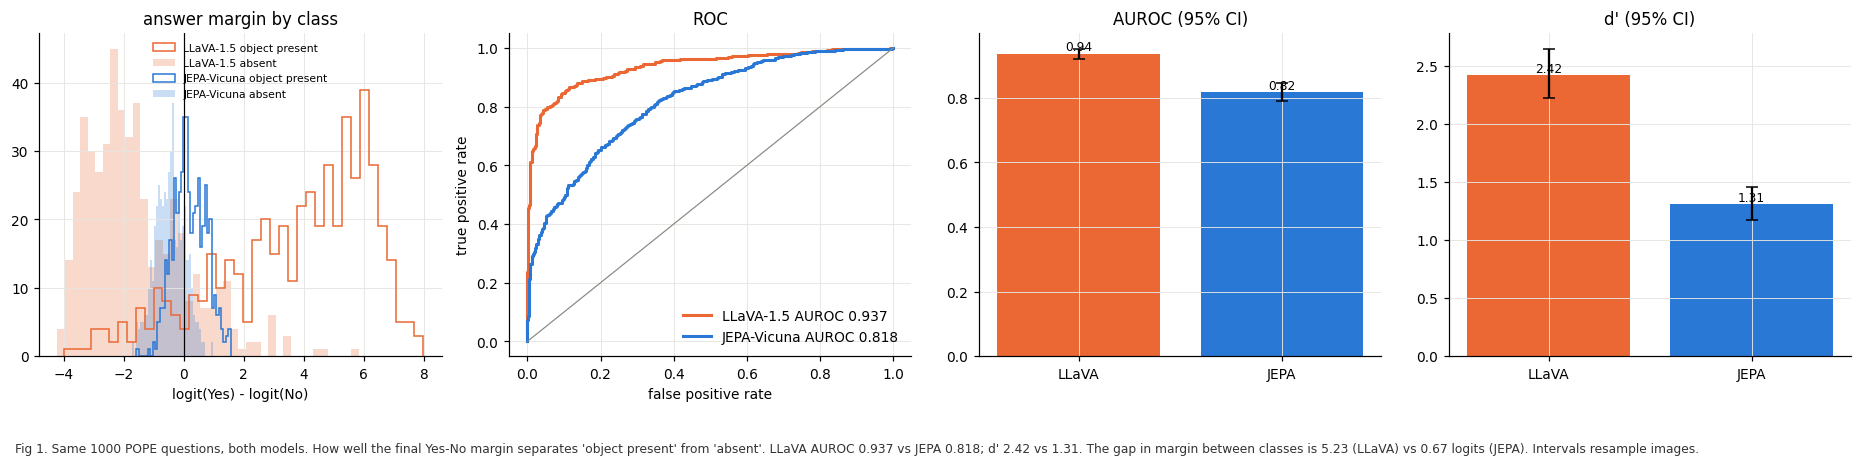

In [17]:
# D1. BEHAVIOUR: how well does each model answer, on the SAME questions?
if CL is not None and CJ is not None:
  try:
    rows = []
    for nm, C in (("LLaVA-1.5", CL), ("JEPA-Vicuna", CJ)):
        for sub, sl in (("all %d" % NC, slice(None)), ("first 400", slice(0, 400)), ("first 300", slice(0, 300))):
            b = beh(C["LD"][sl], YC[sl]); b.update(model=nm, subset=sub, corr_auroc=auroc(C["LDC"][sl], YC[sl])); rows.append(b)
    BEH = pd.DataFrame(rows)[["model", "subset", "n", "auroc", "dprime", "acc", "yes_rate", "gap", "sd", "halluc", "miss", "corr_auroc"]]
    print(BEH.round(3).to_string(index=False))
    def _d(f):
        v = np.array([f(b) for b in BOOT_C]); return f(np.arange(NC)), v
    au = lambda C: (lambda ix: auroc(C["LD"][ix], YC[ix])); dp = lambda C: (lambda ix: dprime(C["LD"][ix], YC[ix]))
    dA, vA = _d(lambda ix: au(CL)(ix) - au(CJ)(ix)); dD, vD = _d(lambda ix: dp(CL)(ix) - dp(CJ)(ix))
    BEH_RES = dict(auroc_L=au(CL)(np.arange(NC)), auroc_J=au(CJ)(np.arange(NC)), d_auroc=dA, d_auroc_ci=ci(vA), d_dprime=dD, d_dprime_ci=ci(vD),
                   dprime_L=dp(CL)(np.arange(NC)), dprime_J=dp(CJ)(np.arange(NC)), gap_L=beh(CL["LD"], YC)["gap"], gap_J=beh(CJ["LD"], YC)["gap"])
    print(f"\nAUROC LLaVA - JEPA = {dA:+.3f} {fmt_ci(vA)} | d' LLaVA - JEPA = {dD:+.2f} {fmt_ci(vD)} (image-cluster bootstrap)")
    # Rohan's 3000-question run as a cross-check of our LLaVA numbers
    RD = load_rohan_dla()
    if RD:
        q3 = list(RD); ld3 = np.array([float(RD[q]["logit_diff"]) for q in q3]); y3 = np.array([str(RD[q]["ground_truth_answer"]).strip().lower() == "yes" for q in q3])
        print("Rohan's dla-llava, all %d POPE questions:" % len(q3), {k: round(v, 3) for k, v in beh(ld3, y3).items()})
        m = [i for i, q in enumerate(QC) if q in RD]; print(f"our LLaVA logit differences vs his on {len(m)} shared questions: max |diff| {np.abs(CL['LD'][m] - np.array([float(RD[QC[i]]['logit_diff']) for i in m])).max():.4f}")
    fig, ax = plt.subplots(1, 4, figsize=(17, 4.2))
    for C, c, nm in ((CL, C_L, "LLaVA-1.5"), (CJ, C_J, "JEPA-Vicuna")):
        x = np.clip(C["LD"], -8, 8); ax[0].hist(x[YC], bins=40, histtype="step", color=c, lw=1.8, label=f"{nm} object present"); ax[0].hist(x[~YC], bins=40, histtype="stepfilled", color=c, alpha=0.25, label=f"{nm} absent")
        s = np.argsort(-C["LD"]); tpr = np.cumsum(YC[s]) / YC.sum(); fpr = np.cumsum(~YC[s]) / (~YC).sum(); ax[1].plot(fpr, tpr, color=c, lw=2, label=f"{nm} AUROC {auroc(C['LD'], YC):.3f}")
    ax[0].axvline(0, color="k", lw=0.8); ax[0].set_xlabel("logit(Yes) - logit(No)"); ax[0].set_title("answer margin by class"); ax[0].legend(fontsize=7, frameon=False)
    ax[1].plot([0, 1], [0, 1], color=C_G, lw=0.8); ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate"); ax[1].set_title("ROC"); ax[1].legend(frameon=False)
    for j, (k_, lab) in enumerate((("auroc", "AUROC"), ("dprime", "d'"))):
        a = ax[2 + j]; vals = [BEH_RES[f"{k_}_L"], BEH_RES[f"{k_}_J"]]; f_ = au if k_ == "auroc" else dp
        errs = [np.percentile([f_(C)(b) for b in BOOT_C], [2.5, 97.5]) for C in (CL, CJ)]
        a.bar([0, 1], vals, color=[C_L, C_J], yerr=[[v - e[0] for v, e in zip(vals, errs)], [e[1] - v for v, e in zip(vals, errs)]], capsize=4); a.set_xticks([0, 1]); a.set_xticklabels(["LLaVA", "JEPA"]); a.set_title(lab + " (95% CI)")
        for i_, v_ in enumerate(vals): a.text(i_, v_, f"{v_:.2f}", ha="center", va="bottom", fontsize=8)
    finish(fig, "01_behaviour", f"Fig 1. Same {NC} POPE questions, both models. How well the final Yes-No margin separates 'object present' from 'absent'. LLaVA AUROC {BEH_RES['auroc_L']:.3f} vs JEPA {BEH_RES['auroc_J']:.3f}; d' {BEH_RES['dprime_L']:.2f} vs {BEH_RES['dprime_J']:.2f}. The gap in margin between classes is {BEH_RES['gap_L']:.2f} (LLaVA) vs {BEH_RES['gap_J']:.2f} logits (JEPA). Intervals resample images.")
  except Exception:
    import traceback; traceback.print_exc(); print("\n>>> THIS CELL FAILED (traceback above). <<<")
    if not SOFT_FAIL: raise

split-half reliability of the truth-part vector (Spearman-Brown): LLaVA 0.98 | JEPA 0.78
Spearman(truth part, LLaVA vs JEPA) over 1057 components: +0.290 [+0.252, +0.323] | noise-ceiling corrected 0.33
  MLPs only (32) +0.79 | heads only (1024) +0.27 | constants: all +0.29, MLPs +0.82 | top-20 overlap 15 (chance 0.4) | top-50 overlap 29 (chance 2.4)
component  truth LLaVA  truth JEPA  const LLaVA  const JEPA
  L18.mlp        1.559       0.199        -2.12       -1.43
  L28.mlp       -0.655      -0.053        -2.58       -3.70
  L20.mlp        0.606       0.091         2.53        3.11
  L27.mlp       -0.500      -0.067        -0.96       -1.02
  L23.mlp        0.322       0.113         0.04        0.39
  L17.mlp        0.309       0.022         0.70        0.49
    L27H7        0.288       0.010         0.47        0.13
  L29.mlp       -0.266       0.001        -0.32       -0.67
    L16H0        0.252       0.023         0.82        0.68
  L16.mlp        0.251       0.039        -0.07 

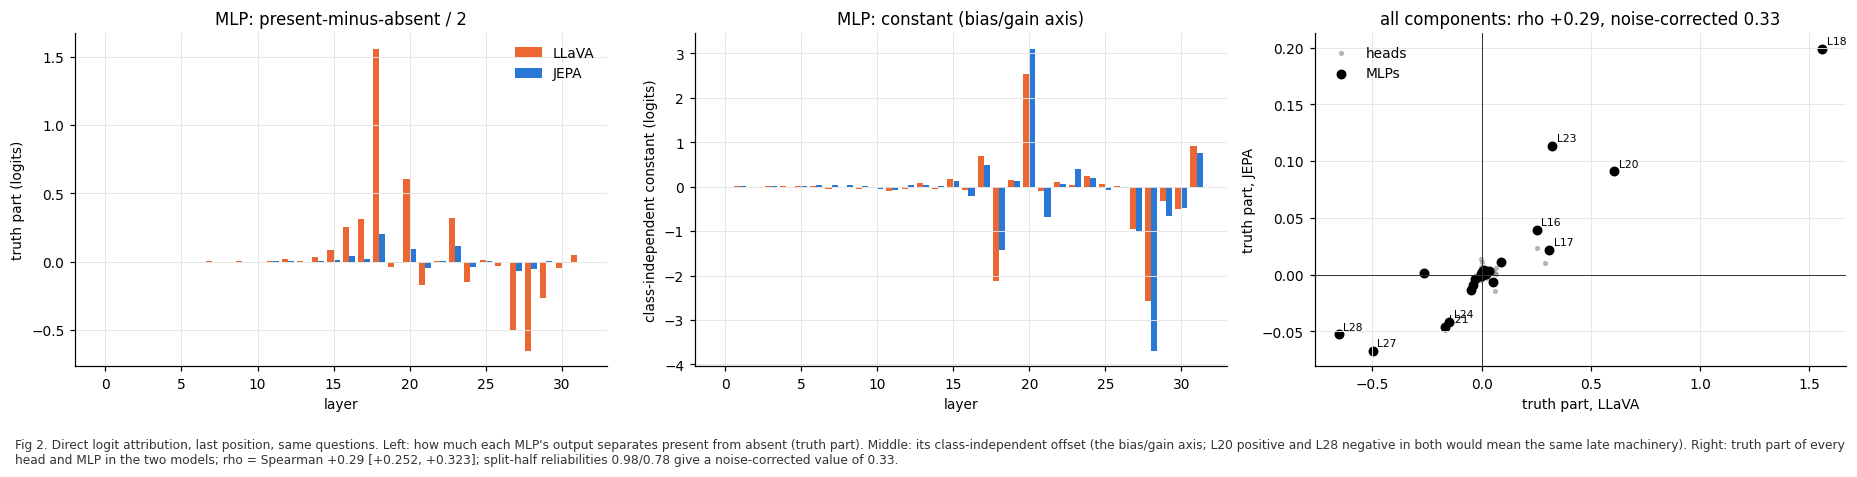

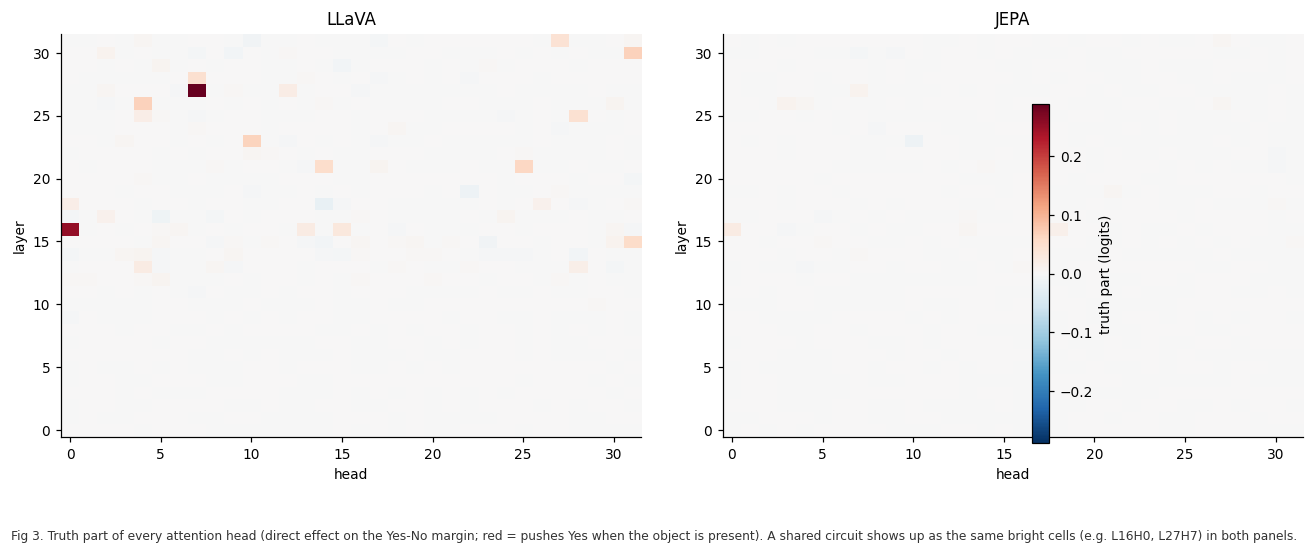

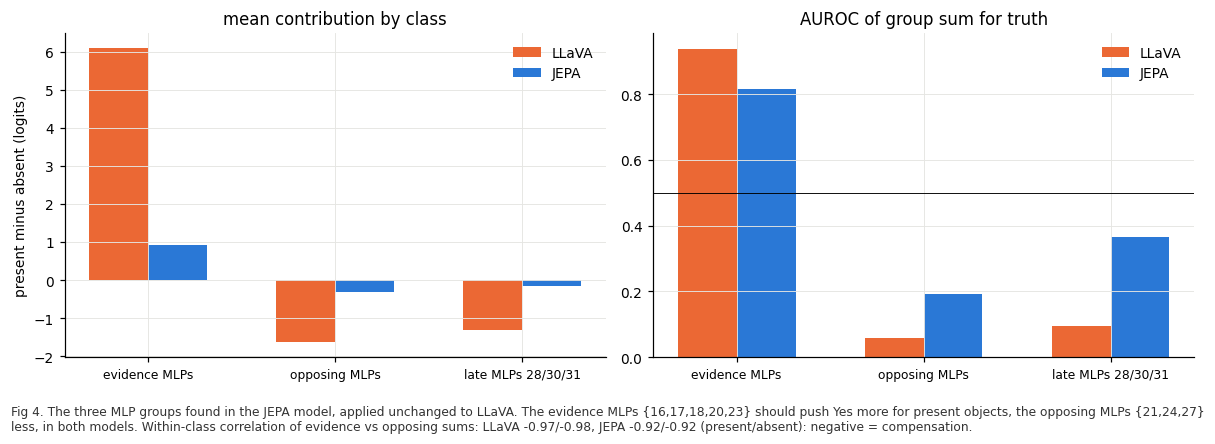

In [18]:
# D2. DIRECT-EFFECT SIGNATURE: which components write the Yes-No margin, and do the two models use the same ones?
if CL is not None and CJ is not None:
  try:
    nl, nh = CL["ATTN"].shape[1:]; NAMES = [f"L{l}H{h}" for l in range(nl) for h in range(nh)] + [f"L{l}.mlp" for l in range(nl)] + ["embed"]
    FL = np.concatenate([CL["ATTN"].reshape(NC, -1), CL["MLP"], CL["EMB"][:, None]], 1).astype(np.float64); FJ = np.concatenate([CJ["ATTN"].reshape(NC, -1), CJ["MLP"], CJ["EMB"][:, None]], 1).astype(np.float64)
    def tk(F, y):
        m1, m0 = F[y].mean(0), F[~y].mean(0); return (m1 - m0) / 2, (m1 + m0) / 2          # truth part, class-independent constant
    tL, kL = tk(FL, YC); tJ, kJ = tk(FJ, YC); MLP0 = nl * nh
    sp = lambda a, b: float(spearmanr(a, b)[0])
    # split-half reliability (by image) -> noise ceiling for the cross-model correlation
    rng = np.random.default_rng(0); uimg = np.unique(GC); rel = {"L": [], "J": []}
    for _ in range(40):
        half = set(rng.permutation(uimg)[: len(uimg) // 2]); a = np.array([g in half for g in GC])
        if YC[a].sum() < 5 or (~YC[a]).sum() < 5 or YC[~a].sum() < 5 or (~YC[~a]).sum() < 5: continue
        for nm, F in (("L", FL), ("J", FJ)): rel[nm].append(sp(tk(F[a], YC[a])[0], tk(F[~a], YC[~a])[0]))
    rL_, rJ_ = [2 * np.mean(rel[k_]) / (1 + np.mean(rel[k_])) for k_ in "LJ"]             # Spearman-Brown corrected reliability of each model's truth-part vector
    def stats(ix):
        a, b = tk(FL[ix], YC[ix])[0], tk(FJ[ix], YC[ix])[0]; return sp(a, b)
    rho = sp(tL, tJ); rho_b = np.array([stats(b) for b in BOOT_C[:150]]); rho_star = min(1.0, rho / np.sqrt(max(rL_ * rJ_, 1e-6)))
    rho_mlp = sp(tL[MLP0:MLP0 + nl], tJ[MLP0:MLP0 + nl]); rho_head = sp(tL[:MLP0], tJ[:MLP0]); rho_const = sp(kL, kJ); rho_const_mlp = sp(kL[MLP0:MLP0 + nl], kJ[MLP0:MLP0 + nl])
    topn = lambda t, n: set(np.argsort(-np.abs(t))[:n]); ov20 = len(topn(tL, 20) & topn(tJ, 20)); ov50 = len(topn(tL, 50) & topn(tJ, 50))
    print(f"split-half reliability of the truth-part vector (Spearman-Brown): LLaVA {rL_:.2f} | JEPA {rJ_:.2f}")
    print(f"Spearman(truth part, LLaVA vs JEPA) over {len(NAMES)} components: {rho:+.3f} {fmt_ci(rho_b)} | noise-ceiling corrected {rho_star:.2f}")
    print(f"  MLPs only (32) {rho_mlp:+.2f} | heads only (1024) {rho_head:+.2f} | constants: all {rho_const:+.2f}, MLPs {rho_const_mlp:+.2f} | top-20 overlap {ov20} (chance 0.4) | top-50 overlap {ov50} (chance 2.4)")
    show = list(np.argsort(-np.abs(tL))[:12]) + [i for i in np.argsort(-np.abs(tJ))[:12] if i not in set(np.argsort(-np.abs(tL))[:12])]
    print(pd.DataFrame({"component": [NAMES[i] for i in show], "truth LLaVA": tL[show].round(3), "truth JEPA": tJ[show].round(3), "const LLaVA": kL[show].round(2), "const JEPA": kJ[show].round(2)}).to_string(index=False))
    # component groups found for JEPA, applied to both models
    gi = lambda names: [NAMES.index(n) for n in names]; G = {"evidence MLPs": gi(EVID_MLPS), "opposing MLPs": gi(OPP_MLPS), "late MLPs 28/30/31": gi(["L28.mlp", "L30.mlp", "L31.mlp"])}
    GRP = {}
    for nm, F in (("LLaVA", FL), ("JEPA", FJ)):
        s = {g: F[:, ix].sum(1) for g, ix in G.items()}; ev, op = s["evidence MLPs"], s["opposing MLPs"]
        GRP[nm] = dict(auroc={g: auroc(v, YC) for g, v in s.items()}, mean={g: (v[YC].mean(), v[~YC].mean()) for g, v in s.items()},
                       corr_ev_op_pres=float(np.corrcoef(ev[YC], op[YC])[0, 1]), corr_ev_op_abs=float(np.corrcoef(ev[~YC], op[~YC])[0, 1]))
        print(f"{nm}: group-sum AUROC for truth {({k_: round(v, 3) for k_, v in GRP[nm]['auroc'].items()})} | corr(evidence, opposing) within class: present {GRP[nm]['corr_ev_op_pres']:+.2f}, absent {GRP[nm]['corr_ev_op_abs']:+.2f}")
    j20, j28 = NAMES.index("L20.mlp"), NAMES.index("L28.mlp"); print(f"constants L20.mlp: LLaVA {kL[j20]:+.2f} JEPA {kJ[j20]:+.2f} | L28.mlp: LLaVA {kL[j28]:+.2f} JEPA {kJ[j28]:+.2f}")
    DLA_RES = dict(rho=rho, rho_ci=ci(rho_b), rho_star=rho_star, rel_L=rL_, rel_J=rJ_, rho_mlp=rho_mlp, rho_head=rho_head, rho_const=rho_const, ov20=ov20, ov50=ov50, GRP=GRP,
                   l20=(kL[j20], kJ[j20]), l28=(kL[j28], kJ[j28]))
    # ---- figures ----
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.3)); x = np.arange(nl)
    ax[0].bar(x - 0.2, tL[MLP0:MLP0 + nl], 0.4, color=C_L, label="LLaVA"); ax[0].bar(x + 0.2, tJ[MLP0:MLP0 + nl], 0.4, color=C_J, label="JEPA"); ax[0].set_xlabel("layer"); ax[0].set_ylabel("truth part (logits)"); ax[0].set_title("MLP: present-minus-absent / 2"); ax[0].legend(frameon=False)
    ax[1].bar(x - 0.2, kL[MLP0:MLP0 + nl], 0.4, color=C_L); ax[1].bar(x + 0.2, kJ[MLP0:MLP0 + nl], 0.4, color=C_J); ax[1].set_xlabel("layer"); ax[1].set_ylabel("class-independent constant (logits)"); ax[1].set_title("MLP: constant (bias/gain axis)")
    ax[2].scatter(tL[:MLP0], tJ[:MLP0], s=6, color=C_G, alpha=0.5, label="heads"); ax[2].scatter(tL[MLP0:MLP0 + nl], tJ[MLP0:MLP0 + nl], s=30, color="k", label="MLPs")
    for l in (16, 17, 18, 20, 21, 23, 24, 27, 28): ax[2].annotate(f"L{l}", (tL[MLP0 + l], tJ[MLP0 + l]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax[2].axhline(0, color="k", lw=0.5); ax[2].axvline(0, color="k", lw=0.5); ax[2].set_xlabel("truth part, LLaVA"); ax[2].set_ylabel("truth part, JEPA"); ax[2].set_title(f"all components: rho {rho:+.2f}, noise-corrected {rho_star:.2f}"); ax[2].legend(frameon=False)
    finish(fig, "02_dla_mlp", f"Fig 2. Direct logit attribution, last position, same questions. Left: how much each MLP's output separates present from absent (truth part). Middle: its class-independent offset (the bias/gain axis; L20 positive and L28 negative in both would mean the same late machinery). Right: truth part of every head and MLP in the two models; rho = Spearman {rho:+.2f} {fmt_ci(rho_b)}; split-half reliabilities {rL_:.2f}/{rJ_:.2f} give a noise-corrected value of {rho_star:.2f}.")
    fig, ax = plt.subplots(1, 2, figsize=(12, 5)); lim = max(np.abs(tL[:MLP0]).max(), np.abs(tJ[:MLP0]).max())
    for a, t, nm in zip(ax, (tL, tJ), ("LLaVA", "JEPA")):
        im = a.imshow(t[:MLP0].reshape(nl, nh), origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto"); a.set_title(nm); a.set_xlabel("head"); a.set_ylabel("layer"); a.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8, label="truth part (logits)")
    finish(fig, "03_dla_heads", "Fig 3. Truth part of every attention head (direct effect on the Yes-No margin; red = pushes Yes when the object is present). A shared circuit shows up as the same bright cells (e.g. L16H0, L27H7) in both panels.")
    fig, ax = plt.subplots(1, 2, figsize=(11, 4)); w = 0.35
    for a, (key, ttl) in zip(ax, (("mean", "mean contribution by class"), ("auroc", "AUROC of group sum for truth"))):
        for i_, (nm, c) in enumerate((("LLaVA", C_L), ("JEPA", C_J))):
            for g_i, g in enumerate(G):
                if key == "mean": a.bar(g_i + (i_ - 0.5) * w * 0.9, GRP[nm]["mean"][g][0] - GRP[nm]["mean"][g][1], w * 0.9, color=c, label=nm if g_i == 0 else None)
                else: a.bar(g_i + (i_ - 0.5) * w * 0.9, GRP[nm]["auroc"][g], w * 0.9, color=c, label=nm if g_i == 0 else None)
        a.set_xticks(range(len(G))); a.set_xticklabels(list(G), fontsize=8); a.set_title(ttl); a.legend(frameon=False)
    ax[0].set_ylabel("present minus absent (logits)"); ax[1].axhline(0.5, color="k", lw=0.6)
    finish(fig, "04_dla_groups", f"Fig 4. The three MLP groups found in the JEPA model, applied unchanged to LLaVA. The evidence MLPs {{16,17,18,20,23}} should push Yes more for present objects, the opposing MLPs {{21,24,27}} less, in both models. Within-class correlation of evidence vs opposing sums: LLaVA {GRP['LLaVA']['corr_ev_op_pres']:+.2f}/{GRP['LLaVA']['corr_ev_op_abs']:+.2f}, JEPA {GRP['JEPA']['corr_ev_op_pres']:+.2f}/{GRP['JEPA']['corr_ev_op_abs']:+.2f} (present/absent): negative = compensation.")
  except Exception:
    import traceback; traceback.print_exc(); print("\n>>> THIS CELL FAILED (traceback above). <<<")
    if not SOFT_FAIL: raise

[LLaVA probes (layer sweep)] 1/17 | 0.0 min elapsed, ETA 0.1 min 
[LLaVA probes (layer sweep)] 5/17 | 0.4 min elapsed, ETA 0.9 min 
[LLaVA probes (layer sweep)] 10/17 | 0.8 min elapsed, ETA 0.6 min 
[LLaVA probes (layer sweep)] 14/17 | 1.2 min elapsed, ETA 0.2 min 
[LLaVA probes (layer sweep)] 17/17 | 1.4 min elapsed, ETA 0.0 min 
LLaVA: probe AUROC by layer L0:0.50 L2:0.69 L4:0.74 L6:0.85 L8:0.94 L10:0.97 L12:0.97 L14:0.97 L16:0.97 L18:0.97 L20:0.96 L22:0.97 L24:0.97 L26:0.97 L28:0.97 L30:0.97 L32:0.97 | best L28 0.969 | model output AUROC 0.937 | 1.4 min
[JEPA probes (layer sweep)] 1/17 | 0.0 min elapsed, ETA 0.1 min 
[JEPA probes (layer sweep)] 4/17 | 0.4 min elapsed, ETA 1.2 min 
[JEPA probes (layer sweep)] 8/17 | 0.8 min elapsed, ETA 0.9 min 
[JEPA probes (layer sweep)] 12/17 | 1.2 min elapsed, ETA 0.5 min 
[JEPA probes (layer sweep)] 16/17 | 1.5 min elapsed, ETA 0.1 min 
[JEPA probes (layer sweep)] 17/17 | 1.6 min elapsed, ETA 0.0 min 
JEPA: probe AUROC by layer L0:0.50 L2:0.65 L

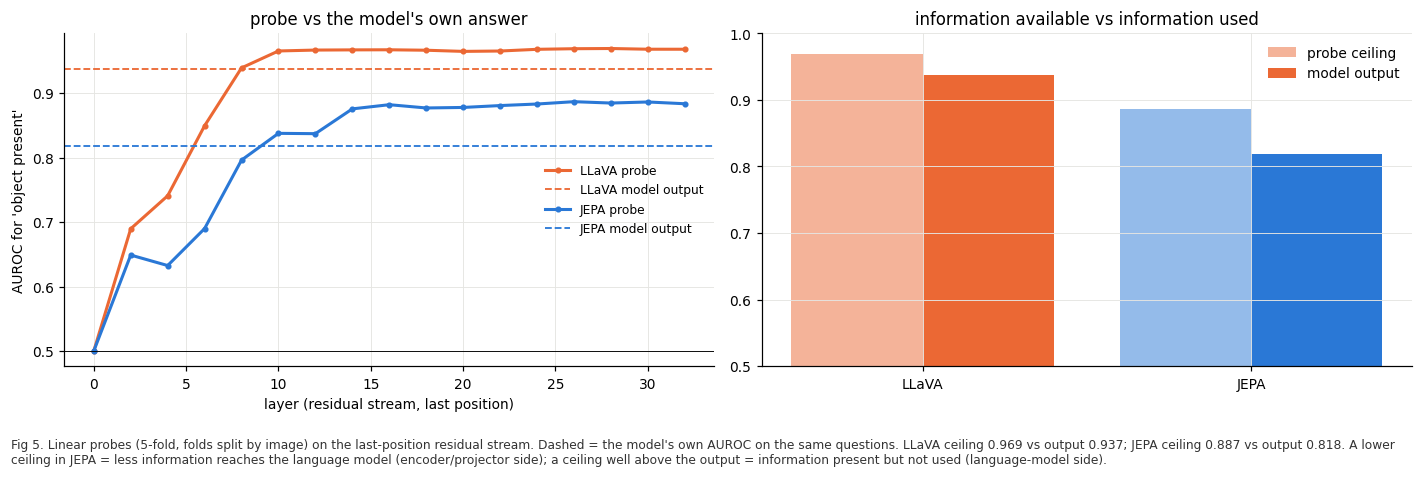

In [19]:
# D3. INFORMATION vs USE. A linear probe on the last-position residual stream (question-aware) asks: is 'object present?' decodable at layer l, and does the model's own answer use it?
if CL is not None and CJ is not None:
  try:
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import GroupKFold
    from sklearn.preprocessing import StandardScaler
    PROBE_LAYERS = list(range(0, CL["RES"].shape[1], 2)); PROBE_C = 0.02
    def probe_oof(R, l, C=PROBE_C):
        X = R[:, l, :].astype(np.float32); oof = np.zeros(NC)
        for tr, te in GroupKFold(5).split(X, YC, GC):
            sc = StandardScaler().fit(X[tr]); clf = LogisticRegression(C=C, max_iter=300, class_weight="balanced").fit(sc.transform(X[tr]), YC[tr]); oof[te] = clf.decision_function(sc.transform(X[te]))
        return oof
    PR = {}
    for nm, Cc in (("LLaVA", CL), ("JEPA", CJ)):
        t0 = time.time(); _p = Prog(f"{nm} probes (layer sweep)", len(PROBE_LAYERS), 0, 20); oofs = {}
        for _i, l in enumerate(PROBE_LAYERS): oofs[l] = probe_oof(Cc["RES"], l); _p(_i)
        au_l = {l: auroc(o, YC) for l, o in oofs.items()}
        best = max(au_l, key=au_l.get); PR[nm] = dict(oof=oofs, auroc=au_l, best=best, out_auroc=auroc(Cc["LD"], YC))
        print(f"{nm}: probe AUROC by layer " + " ".join(f"L{l}:{v:.2f}" for l, v in au_l.items()) + f" | best L{best} {au_l[best]:.3f} | model output AUROC {PR[nm]['out_auroc']:.3f} | {(time.time() - t0) / 60:.1f} min")
    # shuffled-label control and C sensitivity on each model's best layer
    for nm, Cc in (("LLaVA", CL), ("JEPA", CJ)):
        l = PR[nm]["best"]; yperm = np.random.default_rng(0).permutation(YC); Xl = Cc["RES"][:, l, :].astype(np.float32); oof = np.zeros(NC)
        for tr, te in GroupKFold(5).split(Xl, yperm, GC):
            sc = StandardScaler().fit(Xl[tr]); clf = LogisticRegression(C=PROBE_C, max_iter=300, class_weight="balanced").fit(sc.transform(Xl[tr]), yperm[tr]); oof[te] = clf.decision_function(sc.transform(Xl[te]))
        sens = {c_: round(auroc(probe_oof(Cc["RES"], l, c_), YC), 3) for c_ in (0.002, 0.2)}
        print(f"  {nm} layer {l}: shuffled-label probe AUROC {auroc(oof, yperm):.3f} (should be ~0.5) | C sensitivity {sens} (C={PROBE_C}: {PR[nm]['auroc'][l]:.3f})")
    # ceilings with image-cluster CIs, and the information-vs-use gap
    def ceil_ci(nm): o = PR[nm]["oof"][PR[nm]["best"]]; return np.array([auroc(o[b], YC[b]) for b in BOOT_C])
    cb = {nm: ceil_ci(nm) for nm in PR}; ob = {nm: np.array([auroc((CL if nm == "LLaVA" else CJ)["LD"][b], YC[b]) for b in BOOT_C]) for nm in PR}
    PROBE_RES = {}
    for nm in PR:
        c0, o0 = PR[nm]["auroc"][PR[nm]["best"]], PR[nm]["out_auroc"]; gap_b = cb[nm] - ob[nm]
        PROBE_RES[nm] = dict(best=PR[nm]["best"], ceiling=c0, ceiling_ci=ci(cb[nm]), output=o0, gap=c0 - o0, gap_ci=ci(gap_b))
        print(f"{nm}: probe ceiling {c0:.3f} {fmt_ci(cb[nm])} (layer {PR[nm]['best']}) | output {o0:.3f} | information-not-used gap {c0 - o0:+.3f} {fmt_ci(gap_b)}")
    dcl = cb["JEPA"] - cb["LLaVA"]; PROBE_RES["diff_ceiling_J_minus_L"] = (PR["JEPA"]["auroc"][PR["JEPA"]["best"]] - PR["LLaVA"]["auroc"][PR["LLaVA"]["best"]], ci(dcl))
    print(f"probe ceiling JEPA - LLaVA = {PROBE_RES['diff_ceiling_J_minus_L'][0]:+.3f} {fmt_ci(dcl)}")
    # error-level split: among the model's wrong answers, how many does the probe (out-of-fold, best layer) get right?
    for nm, Cc in (("LLaVA", CL), ("JEPA", CJ)):
        pred_p = PR[nm]["oof"][PR[nm]["best"]] > 0; pred_m = Cc["LD"] > 0; fy = pred_m & ~YC; fn = ~pred_m & YC; err = pred_m != YC
        f = lambda m: float((pred_p[m] == YC[m]).mean()) if m.sum() else float("nan")
        bs = np.array([float((pred_p[b][err[b]] == YC[b][err[b]]).mean()) for b in BOOT_C if err[b].sum()])
        PROBE_RES[nm].update(rec_false_yes=f(fy), rec_false_no=f(fn), rec_all=f(err), rec_all_ci=ci(bs), n_false_yes=int(fy.sum()), n_err=int(err.sum()))
        print(f"{nm}: of {int(err.sum())} model errors the probe is right on {f(err):.2f} {fmt_ci(bs)} | false 'yes' ({int(fy.sum())}): {f(fy):.2f} | false 'no' ({int(fn.sum())}): {f(fn):.2f}")
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
    for nm, c in (("LLaVA", C_L), ("JEPA", C_J)):
        ax[0].plot(PROBE_LAYERS, [PR[nm]["auroc"][l] for l in PROBE_LAYERS], color=c, lw=2, marker="o", ms=3, label=f"{nm} probe"); ax[0].axhline(PR[nm]["out_auroc"], color=c, ls="--", lw=1.2, label=f"{nm} model output")
    ax[0].axhline(0.5, color="k", lw=0.6); ax[0].set_xlabel("layer (residual stream, last position)"); ax[0].set_ylabel("AUROC for 'object present'"); ax[0].set_title("probe vs the model's own answer"); ax[0].legend(frameon=False, fontsize=8)
    names_ = ["LLaVA", "JEPA"]; xx = np.arange(2); ax[1].bar(xx - 0.2, [PROBE_RES[n]["ceiling"] for n in names_], 0.4, color=[C_L, C_J], alpha=0.5, label="probe ceiling"); ax[1].bar(xx + 0.2, [PROBE_RES[n]["output"] for n in names_], 0.4, color=[C_L, C_J], label="model output")
    ax[1].set_xticks(xx); ax[1].set_xticklabels(names_); ax[1].set_ylim(0.5, 1.0); ax[1].legend(frameon=False); ax[1].set_title("information available vs information used")
    finish(fig, "05_probes", f"Fig 5. Linear probes (5-fold, folds split by image) on the last-position residual stream. Dashed = the model's own AUROC on the same questions. LLaVA ceiling {PROBE_RES['LLaVA']['ceiling']:.3f} vs output {PROBE_RES['LLaVA']['output']:.3f}; JEPA ceiling {PROBE_RES['JEPA']['ceiling']:.3f} vs output {PROBE_RES['JEPA']['output']:.3f}. A lower ceiling in JEPA = less information reaches the language model (encoder/projector side); a ceiling well above the output = information present but not used (language-model side).")
  except Exception:
    import traceback; traceback.print_exc(); print("\n>>> THIS CELL FAILED (traceback above). <<<")
    if not SOFT_FAIL: raise

130 configs in common
baseline AUROC on these 400 questions: LLaVA 0.927 | JEPA 0.812
                      config model  d_auroc  ci_lo  ci_hi  rand_mean  rand_sd  rand_min      z  below_min  d_mean_logit
               evidence MLPs LLaVA   -0.002 -0.005  0.003      0.000    0.003    -0.004 -0.796      False        -0.333
               evidence MLPs  JEPA   -0.057 -0.074 -0.037     -0.006    0.009    -0.021 -5.877       True        -0.012
               opposing MLPs LLaVA   -0.000 -0.001  0.001     -0.000    0.003    -0.004  0.043      False         0.016
               opposing MLPs  JEPA    0.005  0.001  0.010     -0.009    0.008    -0.025  1.719      False        -0.001
        answer-reactive MLPs LLaVA   -0.003 -0.005 -0.001      0.000    0.001    -0.001 -3.400       True         0.037
        answer-reactive MLPs  JEPA   -0.018 -0.030 -0.008     -0.002    0.006    -0.015 -2.424       True        -0.003
              evidence heads LLaVA    0.000 -0.002  0.003     -0.000    0.

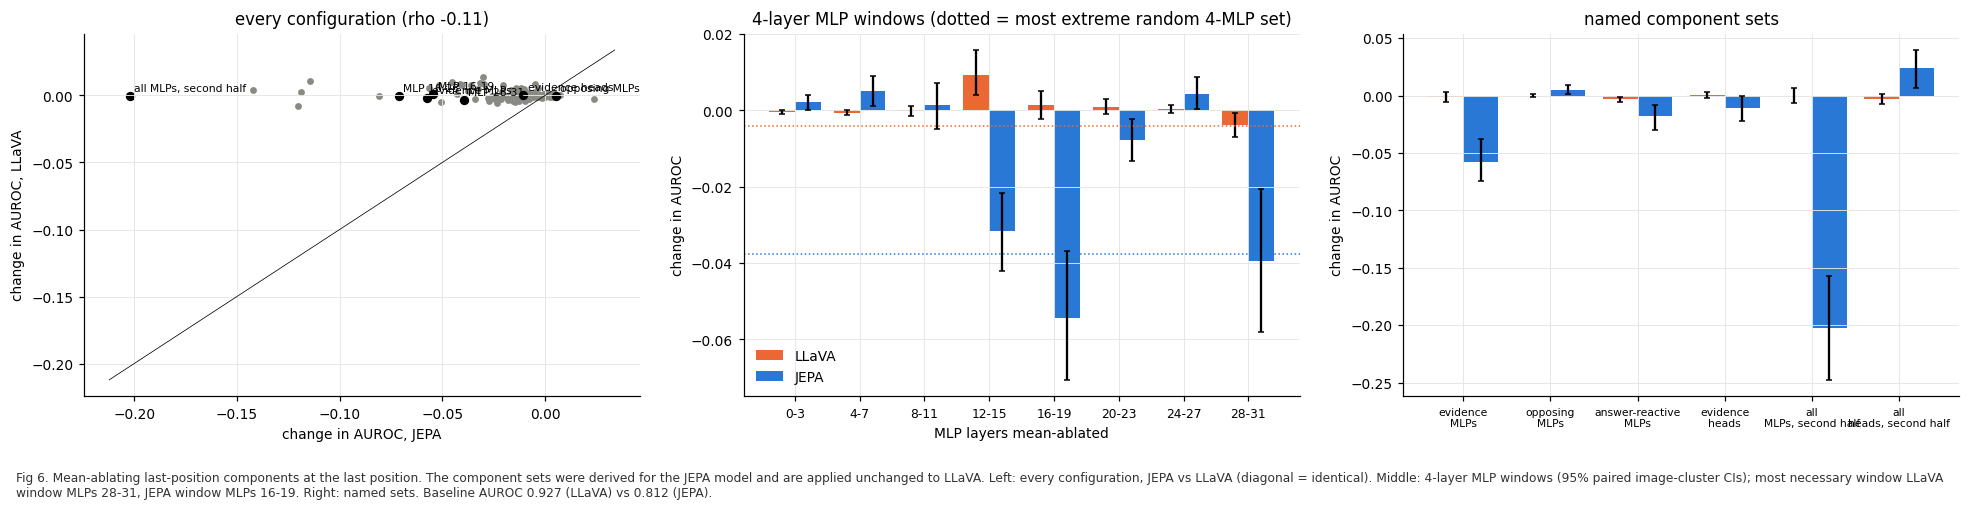

In [20]:
# D4. NECESSITY: mean-ablating the same components in both models (step 6 / 6x). Same questions, same random controls.
if ABL_L is not None and OLD["abl"]:
  try:
    zA = dict(np.load(OLD["abl"], allow_pickle=True)); zX = dict(np.load(OLD["loc"], allow_pickle=True)) if OLD["loc"] else None
    labJ = {str(l): zA["LD"][:, j] for j, l in enumerate(zA["labels"])}
    if zX is not None: labJ.update({str(l): zX["LD"][:, j] for j, l in enumerate(zX["labels"]) if str(l) not in labJ})
    labL = {str(l): ABL_L["LD"][:, j] for j, l in enumerate(ABL_L["labels"])}
    q6 = [str(q) for q in ABL_L["qids"]]; y6 = np.array([g == "yes" for g in ABL_L["gt"]]); n6 = len(q6)
    assert list(map(str, zA["qids"][:n6])) == q6, "JEPA and LLaVA ablations are not on the same questions"
    B6 = cluster_boot([IMG_OF[q] for q in q6], B=300); common = [l for l in labL if l in labJ]; print(len(common), "configs in common")
    def dtab(lab):
        base = lab["baseline"]; a0 = auroc(base, y6); rows = {}
        for l in common:
            v = lab[l]; d = auroc(v, y6) - a0; bt = np.array([auroc(v[b], y6[b]) - auroc(base[b], y6[b]) for b in B6]); rows[l] = (d, ci(bt)[0], ci(bt)[1], float(np.mean(v - base)))
        return a0, rows
    a0L, tL_ = dtab(labL); a0J, tJ_ = dtab(labJ); print(f"baseline AUROC on these {n6} questions: LLaVA {a0L:.3f} | JEPA {a0J:.3f}")
    def rand_stats(rows, pat):
        v = np.array([rows[l][0] for l in common if re.fullmatch(pat, l)]); return (v.mean(), v.std(ddof=1), v.min(), len(v)) if len(v) else (np.nan,) * 3 + (0,)
    SPEC = [("evidence MLPs", r"random like evidence MLPs #\d+"), ("opposing MLPs", r"random like opposing MLPs #\d+"), ("answer-reactive MLPs", r"random like answer-reactive MLPs #\d+"),
            ("evidence heads", r"random like evidence heads #\d+"), ("bias heads", r"random like bias heads #\d+"), ("all MLPs, second half", r"random 16 MLPs #\d+"),
            ("2nd half minus evidence MLPs", r"random 11 non-evidence MLPs #\d+")] + [(f"window MLPs {lo}-{lo + 3}", r"random 4 MLPs #\d+") for lo in range(0, 32, 4)] + [(f"window MLPs {lo}-{lo + 7}", r"random 8 MLPs #\d+") for lo in range(0, 32, 8)]
    rows = []
    for lab, pat in SPEC:
        if lab not in common: continue
        for nm, T in (("LLaVA", tL_), ("JEPA", tJ_)):
            m_, s_, mn_, k_ = rand_stats(T, pat); d, lo, hi, dm = T[lab]; rows.append(dict(config=lab, model=nm, d_auroc=d, ci_lo=lo, ci_hi=hi, rand_mean=m_, rand_sd=s_, rand_min=mn_, z=(d - m_) / s_ if s_ > 0 else np.nan, below_min=bool(d < mn_), d_mean_logit=dm))
    ABL_TAB = pd.DataFrame(rows); pd.set_option("display.width", 250); print(ABL_TAB.round(3).to_string(index=False))
    sub = ABL_TAB[ABL_TAB.config.str.startswith("window MLPs")]; w4 = [f"window MLPs {lo}-{lo + 3}" for lo in range(0, 32, 4)]
    pl = [tL_[w][0] for w in w4 if w in tL_]; pj = [tJ_[w][0] for w in w4 if w in tJ_]
    rho_w = spearmanr(pl, pj)[0] if len(pl) == 8 else np.nan; topL = w4[int(np.argmin(pl))] if pl else None; topJ = w4[int(np.argmin(pj))] if pj else None
    allc = [l for l in common if l != "baseline"]; rho_all = spearmanr([tL_[l][0] for l in allc], [tJ_[l][0] for l in allc])[0]
    ABL_RES = dict(rho_windows=rho_w, top_window_L=topL, top_window_J=topJ, rho_all=rho_all, evid_L=ABL_TAB[(ABL_TAB.config == "evidence MLPs") & (ABL_TAB.model == "LLaVA")].iloc[0].to_dict() if (ABL_TAB.config == "evidence MLPs").any() else None,
                   evid_J=ABL_TAB[(ABL_TAB.config == "evidence MLPs") & (ABL_TAB.model == "JEPA")].iloc[0].to_dict() if (ABL_TAB.config == "evidence MLPs").any() else None, a0L=a0L, a0J=a0J)
    print(f"\nmost necessary 4-layer MLP window: LLaVA {topL} | JEPA {topJ} | Spearman of the 8 window effects {rho_w:+.2f} | Spearman over all {len(allc)} configs {rho_all:+.2f}")
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
    xs = [tJ_[l][0] for l in allc]; ys = [tL_[l][0] for l in allc]; ax[0].scatter(xs, ys, s=12, color=C_G); lim = [min(xs + ys) - 0.01, max(xs + ys) + 0.01]; ax[0].plot(lim, lim, color="k", lw=0.5)
    for l in ("evidence MLPs", "opposing MLPs", "all MLPs, second half", "window MLPs 16-19", "window MLPs 28-31", "window MLPs 16-23", "evidence heads"):
        if l in tJ_ and l in tL_: ax[0].annotate(l.replace("window MLPs ", "MLP "), (tJ_[l][0], tL_[l][0]), fontsize=7, xytext=(3, 3), textcoords="offset points"); ax[0].scatter([tJ_[l][0]], [tL_[l][0]], s=26, color="k")
    ax[0].set_xlabel("change in AUROC, JEPA"); ax[0].set_ylabel("change in AUROC, LLaVA"); ax[0].set_title(f"every configuration (rho {rho_all:+.2f})")
    wl = [8 * i for i in range(4)]; lab8 = [f"window MLPs {lo}-{lo + 3}" for lo in range(0, 32, 4)]; xx = np.arange(8)
    for off, (T, c, nm) in zip((-0.2, 0.2), ((tL_, C_L, "LLaVA"), (tJ_, C_J, "JEPA"))): ax[1].bar(xx + off, [T[l][0] for l in lab8], 0.4, color=c, label=nm, yerr=[[T[l][0] - T[l][1] for l in lab8], [T[l][2] - T[l][0] for l in lab8]], capsize=2)
    for nm, T, c in (("LLaVA", tL_, C_L), ("JEPA", tJ_, C_J)):
        rs = rand_stats(T, r"random 4 MLPs #\d+"); ax[1].axhline(rs[2], color=c, ls=":", lw=1)
    ax[1].set_xticks(xx); ax[1].set_xticklabels([l.replace("window MLPs ", "") for l in lab8], fontsize=8); ax[1].set_xlabel("MLP layers mean-ablated"); ax[1].set_ylabel("change in AUROC"); ax[1].set_title("4-layer MLP windows (dotted = most extreme random 4-MLP set)"); ax[1].legend(frameon=False)
    keyc = [l for l in ("evidence MLPs", "opposing MLPs", "answer-reactive MLPs", "evidence heads", "all MLPs, second half", "all heads, second half") if l in tJ_ and l in tL_]; xx = np.arange(len(keyc))
    for off, (T, c, nm) in zip((-0.2, 0.2), ((tL_, C_L, "LLaVA"), (tJ_, C_J, "JEPA"))): ax[2].bar(xx + off, [T[l][0] for l in keyc], 0.4, color=c, label=nm, yerr=[[T[l][0] - T[l][1] for l in keyc], [T[l][2] - T[l][0] for l in keyc]], capsize=2)
    ax[2].set_xticks(xx); ax[2].set_xticklabels([k.replace(" ", "\n", 1) for k in keyc], fontsize=7); ax[2].set_title("named component sets"); ax[2].set_ylabel("change in AUROC")
    finish(fig, "06_ablation", f"Fig 6. Mean-ablating last-position components at the last position. The component sets were derived for the JEPA model and are applied unchanged to LLaVA. Left: every configuration, JEPA vs LLaVA (diagonal = identical). Middle: 4-layer MLP windows (95% paired image-cluster CIs); most necessary window LLaVA {topL}, JEPA {topJ}. Right: named sets. Baseline AUROC {a0L:.3f} (LLaVA) vs {a0J:.3f} (JEPA).")
  except Exception:
    import traceback; traceback.print_exc(); print("\n>>> THIS CELL FAILED (traceback above). <<<")
    if not SOFT_FAIL: raise
else:
    print('D4 skipped: needs llava_ablation.npz (Part B) AND your earlier JEPA files meanablation_results.npz / mlp_localisation.npz (attach dla-jepa-vicuna-noise).')

In [21]:
# D5. ROUTE: patching corrupted activations (step 7). Where does the image information enter, and through which positions?
if PAT_L is not None and OLD["patch"]:
  try:
    PJ = dict(np.load(OLD["patch"], allow_pickle=True)); n7 = len(PAT_L["gt"]); assert PJ["LD0"].shape[0] >= n7
    assert list(map(str, PAT_L["qids"])) == [str(q) for q in ABL_L["qids"][:n7]] if ABL_L is not None else True
    y7 = np.array([g == "yes" for g in PAT_L["gt"]]); sg = np.where(y7, 1.0, -1.0); B7 = cluster_boot([IMG_OF[str(q)] for q in PAT_L["qids"]], B=400); WN = ["0-7", "8-15", "16-19", "20-23", "24-27", "28-31"]
    def ptab(P, n):
        LD0, LDC, LAST, KV = P["LD0"][:n], P["LDC"][:n], P["LAST"][:n], P["KV"][:n]; tot_i = sg * (LDC - LD0); tot = tot_i.mean(); rows = []
        def frac(A):
            s_i = sg * (A - LD0); return s_i.mean() / tot, np.array([s_i[b].mean() / tot_i[b].mean() for b in B7])
        for wi, w in enumerate(WN):
            for kind, A, ks in (("last", LAST, ["heads", "MLPs", "both"]), ("kv", KV, ["image", "text", "both"])):
                for ki, kn in enumerate(ks):
                    f, bt = frac(A[:, wi, ki]); rows.append(dict(window=w, route=kind, patch=kn, frac=f, lo=ci(bt)[0], hi=ci(bt)[1], auroc=auroc(A[:, wi, ki], y7), yes_rate=float((A[:, wi, ki] > 0).mean())))
        def dfrac(a, b):
            d = (sg * (a - LD0)).mean() - (sg * (b - LD0)).mean(); bt = np.array([((sg * (a - LD0))[ix].mean() - (sg * (b - LD0))[ix].mean()) / tot_i[ix].mean() for ix in B7]); return d / tot, ci(bt)
        return pd.DataFrame(rows), tot, tot_i, dict(text_minus_image_8_15=dfrac(KV[:, 1, 1], KV[:, 1, 0]), text_minus_image_16_19=dfrac(KV[:, 2, 1], KV[:, 2, 0]), text_minus_lastboth_8_15=dfrac(KV[:, 1, 1], LAST[:, 1, 2]), clean=beh(LD0, y7), corr=beh(LDC, y7))
    TL_, totL, _, dL = ptab(PAT_L, n7); TJ_, totJ, _, dJ = ptab(PJ, n7)
    print(f"full-corruption signed shift: LLaVA {totL:+.3f} | JEPA {totJ:+.3f} | clean AUROC {dL['clean']['auroc']:.3f} / {dJ['clean']['auroc']:.3f} | corrupted AUROC {dL['corr']['auroc']:.3f} / {dJ['corr']['auroc']:.3f}")
    M = TL_.merge(TJ_, on=["window", "route", "patch"], suffixes=("_L", "_J")); print(M[["window", "route", "patch", "frac_L", "lo_L", "hi_L", "frac_J", "lo_J", "hi_J"]].round(2).to_string(index=False))
    for k_ in ("text_minus_image_8_15", "text_minus_image_16_19", "text_minus_lastboth_8_15"): print(f"{k_}: LLaVA {dL[k_][0]:+.2f} [{dL[k_][1][0]:+.2f}, {dL[k_][1][1]:+.2f}] | JEPA {dJ[k_][0]:+.2f} [{dJ[k_][1][0]:+.2f}, {dJ[k_][1][1]:+.2f}]")
    best = lambda T, route: T[(T.route == route) & (T.patch != "both")].sort_values("frac").iloc[-1][["window", "patch", "frac"]].tolist()
    PAT_RES = dict(totL=totL, totJ=totJ, dL=dL, dJ=dJ, best_last_L=best(TL_, "last"), best_last_J=best(TJ_, "last"), best_kv_L=best(TL_, "kv"), best_kv_J=best(TJ_, "kv"))
    print("largest single-patch fraction: last position", PAT_RES["best_last_L"], "(LLaVA) /", PAT_RES["best_last_J"], "(JEPA) | K/V", PAT_RES["best_kv_L"], "/", PAT_RES["best_kv_J"])
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.4), sharey=True); xx = np.arange(6)
    for a, (route, patch, ttl) in zip(ax, (("last", "both", "last-position heads+MLPs"), ("kv", "text", "K/V of text positions"), ("kv", "image", "K/V of image tokens"))):
        for off, (T, c, nm) in zip((-0.2, 0.2), ((TL_, C_L, "LLaVA"), (TJ_, C_J, "JEPA"))):
            s = T[(T.route == route) & (T.patch == patch)].set_index("window").loc[WN]; a.bar(xx + off, s.frac, 0.4, color=c, label=nm, yerr=[s.frac - s.lo, s.hi - s.frac], capsize=2)
        a.set_xticks(xx); a.set_xticklabels(WN); a.set_xlabel("layers patched"); a.set_title(ttl); a.axhline(0, color="k", lw=0.6); a.axhline(1, color=C_G, lw=0.6, ls=":")
    ax[0].set_ylabel("fraction of the corruption effect reproduced"); ax[0].legend(frameon=False)
    finish(fig, "07_patching", f"Fig 7. Patching the corrupted run's activations into the clean run, by layer window (n={n7}; 95% image-cluster CIs of the ratio). Left: last-position heads+MLPs. Middle: K/V of text tokens (instruction + question). Right: K/V of image tokens. Same picture in both models = the image information is routed the same way. Full-corruption shift: LLaVA {totL:+.2f}, JEPA {totJ:+.2f} logits.")
  except Exception:
    import traceback; traceback.print_exc(); print("\n>>> THIS CELL FAILED (traceback above). <<<")
    if not SOFT_FAIL: raise
else:
    print('D5 skipped: needs llava_patching.npz (Part B) AND your earlier patching_sweeps.npz (attach dla-jepa-vicuna-noise).')

D5 skipped: needs llava_patching.npz (Part B) AND your earlier patching_sweeps.npz (attach dla-jepa-vicuna-noise).


In [22]:
# D6. (optional) Rohan's LLaVA attribution patching (atp-llava-noising): which positions and layers carry the image effect in LLaVA?
import torch
_atp_files = [f for f in find_all("_batch_*.pt") if "atp-llava-noising" in f]
if _atp_files:
  try:
    ent = []
    for f in sorted(_atp_files):
        for e in torch.load(f, weights_only=False):
            if e.get("ok", True) and e["stratum"] in ("true_yes", "true_no"): ent.append(e)
    print(len(ent), "clean-correct questions with attribution-patching effects")
    GN = ["visual", "text", "tail (last 4)"]
    def prof(sel):
        H = np.mean([-e["head"].numpy().sum(-1) for e in sel], 0)        # (3, 32) support for the image effect from heads, by position group
        Mv = np.mean([-e["mlp"].numpy() for e in sel], 0); return H, Mv
    out = {}
    for nm, sel in (("object", [e for e in ent if e["hallucination_type"] == "object"]), ("all types", ent)):
        if not sel: continue
        H, Mv = prof(sel); tot = H.sum() + Mv.sum(); rows = []
        for wi, (lo, hi) in enumerate(WINDOWS7):
            for g in range(3): rows.append(dict(set=nm, window=f"{lo}-{hi}", group=GN[g], heads=H[g, lo:hi + 1].sum() / tot, mlps=Mv[g, lo:hi + 1].sum() / tot))
        out[nm] = pd.DataFrame(rows); print(f"\n{nm} (n={len(sel)}): share of the first-order image effect by layer window and position group"); print(out[nm].round(3).to_string(index=False))
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True); xx = np.arange(6); cols = {"visual": "#2a78d6", "text": "#1baf7a", "tail (last 4)": "#eb6834"}
    for a, (kind, ttl) in zip(ax, (("heads", "attention heads"), ("mlps", "MLPs"))):
        T = out.get("object", next(iter(out.values()))); bottom = np.zeros(6)
        for g in GN: v = T[T.group == g][kind].to_numpy(); a.bar(xx, v, 0.6, bottom=np.where(v >= 0, bottom, 0), color=cols[g], label=g); bottom = bottom + v
        a.set_xticks(xx); a.set_xticklabels([f"{lo}-{hi}" for lo, hi in WINDOWS7]); a.set_title(ttl); a.set_xlabel("layers"); a.axhline(0, color="k", lw=0.6)
    ax[0].set_ylabel("share of first-order image effect"); ax[0].legend(frameon=False)
    finish(fig, "08_llava_atp", "Fig 8. Rohan's LLaVA attribution patching (noising, first order), object questions: share of the image effect carried by components at image-token positions, text-token positions and the last 4 positions, by layer window. Compare with Fig 7: if text positions dominate in layers 8-19, the route found in JEPA by K/V patching is also what LLaVA's first-order effects show.")
    ATP_RES = {k: v.to_dict("records") for k, v in out.items()}
  except Exception:
    import traceback; traceback.print_exc(); print("\n>>> THIS CELL FAILED (traceback above). <<<")
    if not SOFT_FAIL: raise
else: print("atp-llava-noising not attached: skipping (optional)")

atp-llava-noising not attached: skipping (optional)


In [23]:
# D7. VERDICT: pre-registered criteria evaluated on the results above, plus an auto-generated report
try:
    R = {}; V = []
    def add(name, ok, detail): V.append(dict(criterion=name, passed=(None if ok is None else bool(ok)), detail=detail))
    # ---- mechanism: is the computation the same in both models? ----
    if "ABL_RES" in globals():
        ev = ABL_RES["evid_L"]; add("M1  most necessary MLP window agrees (top window equal, or Spearman over 8 windows >= 0.6)", (ABL_RES["top_window_L"] == ABL_RES["top_window_J"]) or (ABL_RES["rho_windows"] >= 0.6), f"top window LLaVA {ABL_RES['top_window_L']} vs JEPA {ABL_RES['top_window_J']}; Spearman {ABL_RES['rho_windows']:+.2f}")
        if ev: add("M2  the JEPA-derived evidence MLPs drop LLaVA's AUROC more than random sets (z <= -2 or below every random set)", (ev["z"] <= -2) or ev["below_min"], f"LLaVA d_auroc {ev['d_auroc']:+.3f}, z {ev['z']:+.1f} (JEPA {ABL_RES['evid_J']['d_auroc']:+.3f}, z {ABL_RES['evid_J']['z']:+.1f})")
    else: add("M1/M2  ablation comparison", None, "not available (ablation cell not run)")
    if "PAT_RES" in globals():
        a, b = PAT_RES["dL"]["text_minus_image_8_15"], PAT_RES["dJ"]["text_minus_image_8_15"]
        add("M3  information enters through text-token K/V, not image-token K/V, in layers 8-15 (difference CI excludes 0) in BOTH models", (a[1][0] > 0) and (b[1][0] > 0), f"text - image: LLaVA {a[0]:+.2f} [{a[1][0]:+.2f}, {a[1][1]:+.2f}] | JEPA {b[0]:+.2f} [{b[1][0]:+.2f}, {b[1][1]:+.2f}]")
    else: add("M3  K/V route", None, "not available (patching cell not run)")
    if "DLA_RES" in globals():
        add("M4  direct-effect signature similar (noise-corrected Spearman >= 0.6) with the same-sign L20/L28 constants", (DLA_RES["rho_star"] >= 0.6) and (np.sign(DLA_RES["l20"][0]) == np.sign(DLA_RES["l20"][1])) and (np.sign(DLA_RES["l28"][0]) == np.sign(DLA_RES["l28"][1])),
            f"rho {DLA_RES['rho']:+.2f} {tuple(round(x, 2) for x in DLA_RES['rho_ci'])}, corrected {DLA_RES['rho_star']:.2f}; L20 const {DLA_RES['l20'][0]:+.2f}/{DLA_RES['l20'][1]:+.2f}, L28 {DLA_RES['l28'][0]:+.2f}/{DLA_RES['l28'][1]:+.2f}")
        g = DLA_RES["GRP"]; add("M5  evidence and opposing MLP sums are anti-correlated within class (r <= -0.3) in both models (compensation signature)", all(g[m][k] <= -0.3 for m in g for k in ("corr_ev_op_pres", "corr_ev_op_abs")), " | ".join(f"{m}: {g[m]['corr_ev_op_pres']:+.2f}/{g[m]['corr_ev_op_abs']:+.2f}" for m in g))
    else: add("M4/M5  DLA comparison", None, "not available")
    mech = [v["passed"] for v in V if v["passed"] is not None]; n_ok = sum(mech)
    mech_verdict = ("SAME mechanism" if n_ok >= len(mech) - 1 and len(mech) >= 4 else ("DIFFERENT mechanism" if n_ok <= 1 and len(mech) >= 4 else "PARTLY the same mechanism")) if mech else "not assessed"
    # ---- information: how much usable information reaches the language model, and how well is it used? ----
    if "PROBE_RES" in globals():
        d, dci = PROBE_RES["diff_ceiling_J_minus_L"]
        add("I1  JEPA's probe ceiling is LOWER than LLaVA's (CI excludes 0): less decodable object information reaches the LM", dci[1] < 0, f"JEPA - LLaVA ceiling {d:+.3f} [{dci[0]:+.3f}, {dci[1]:+.3f}] (LLaVA {PROBE_RES['LLaVA']['ceiling']:.3f}, JEPA {PROBE_RES['JEPA']['ceiling']:.3f})")
        gl, gj = PROBE_RES["LLaVA"]["gap"], PROBE_RES["JEPA"]["gap"]
        add("I2  both models leave decodable information unused (ceiling - output AUROC: CI lower bound > 0.02)", (PROBE_RES["LLaVA"]["gap_ci"][0] > 0.02) and (PROBE_RES["JEPA"]["gap_ci"][0] > 0.02), f"gap LLaVA {gl:+.3f} {tuple(round(x, 3) for x in PROBE_RES['LLaVA']['gap_ci'])}, JEPA {gj:+.3f} {tuple(round(x, 3) for x in PROBE_RES['JEPA']['gap_ci'])}")
        add("I3  JEPA's probe recovers a larger share of its own errors than LLaVA's does (LM-side share of errors)", PROBE_RES["JEPA"]["rec_all"] > PROBE_RES["LLaVA"]["rec_all"], f"share of model errors the probe gets right: JEPA {PROBE_RES['JEPA']['rec_all']:.2f} {tuple(round(x, 2) for x in PROBE_RES['JEPA']['rec_all_ci'])}, LLaVA {PROBE_RES['LLaVA']['rec_all']:.2f} {tuple(round(x, 2) for x in PROBE_RES['LLaVA']['rec_all_ci'])}")
    if "BEH_RES" in globals(): add("I4  LLaVA separates the classes better than JEPA (AUROC difference CI excludes 0)", BEH_RES["d_auroc_ci"][0] > 0, f"AUROC LLaVA - JEPA {BEH_RES['d_auroc']:+.3f} {tuple(round(x, 3) for x in BEH_RES['d_auroc_ci'])}; d' {BEH_RES['dprime_L']:.2f} vs {BEH_RES['dprime_J']:.2f}")
    VT = pd.DataFrame(V); pd.set_option("display.max_colwidth", 200, "display.width", 250)
    print(VT.to_string(index=False)); print(f"\nMECHANISM: {n_ok} of {len(mech)} criteria met -> {mech_verdict}")
    info = {v["criterion"][:2]: v["passed"] for v in V if v["criterion"][0] == "I"}; enc_lim = info.get("I1"); unused = info.get("I2")
    lines = []
    lines.append(f"Mechanism ({n_ok}/{len(mech)} criteria): {mech_verdict}. " + ("The late-layer circuit and the routing of image information look the same with a CLIP encoder and with a JEPA encoder, so the way the language model turns evidence into a Yes/No answer is not created by the encoder." if mech_verdict == "SAME mechanism" else "Parts of the computation differ between the two models; see the failed criteria."))
    if enc_lim is not None:
        _hi = dci[0] > 0 if "dci" in dir() else False
        lines.append("Information reaching the language model: " + ("JEPA's residual stream carries significantly LESS decodable object information than LLaVA's, so the JEPA encoder/projector is at least partly responsible for the weaker discrimination (encoder-driven component)." if enc_lim else ("JEPA's residual stream carries significantly MORE decodable object information than LLaVA's (probe ceiling), so the encoder is not what limits JEPA here." if _hi else "no significant difference in decodable information between the two models, so the performance gap is not explained by what the encoder delivers (language-model-side).")))
    if unused is not None: lines.append("Use of the information: " + ("both models leave decodable information unused at the output, i.e. part of the error is a failure of the language model to use what is present." if unused else "at least one model's output already uses nearly all the information its residual stream contains."))
    lines.append("Caveats: LLaVA's language model was fine-tuned and ours is frozen; the two noise corruptions are calibrated separately (to chance AUROC); the probe is supervised, so 'decodable' means linearly decodable given labels; prompts differ; POPE object questions only (the task's attribute/relation questions are not covered unless HALLUC_TYPE was changed).")
    print("\n" + "\n".join("- " + l for l in lines))
    def _md(T):
        try: return T.to_markdown(index=False)
        except Exception: return T.to_string(index=False)
    rep = ["# Encoder swap: LLaVA-1.5 vs JEPA-Vicuna (auto-generated)\n", "## Verdict\n"] + [f"- {l}" for l in lines] + ["\n## Criteria\n", _md(VT)]
    if "BEH" in globals(): rep += ["\n## Behaviour (same questions)\n", BEH.round(3).to_string(index=False)]
    if "ABL_TAB" in globals(): rep += ["\n## Mean-ablation (change in AUROC; random controls)\n", ABL_TAB.round(3).to_string(index=False)]
    if "M" in globals(): rep += ["\n## Patching (fraction of corruption effect reproduced)\n", M[["window", "route", "patch", "frac_L", "lo_L", "hi_L", "frac_J", "lo_J", "hi_J"]].round(2).to_string(index=False)]
    open(f"{OUT_DIR}/compare_report.md", "w").write("\n".join(map(str, rep)))
    def _clean(o):
        if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
        if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
        if isinstance(o, (np.floating, np.integer)): return o.item()
        if isinstance(o, np.ndarray): return o.tolist()
        return o
    json.dump(_clean({k: globals()[k] for k in ("BEH_RES", "DLA_RES", "PROBE_RES", "ABL_RES", "PAT_RES") if k in globals()}), open(f"{OUT_DIR}/compare_results.json", "w"), indent=1, default=str)
    print(f"\nsaved {OUT_DIR}/compare_report.md, compare_results.json and {len(glob.glob(OUT_DIR + '/figs/*.png'))} figures"); push("analysis results")
except Exception:
    import traceback; traceback.print_exc(); print("\n>>> THIS CELL FAILED (traceback above). <<<")
    if not SOFT_FAIL: raise

                                                                                                              criterion passed                                                                                      detail
                             M1  most necessary MLP window agrees (top window equal, or Spearman over 8 windows >= 0.6)  False                top window LLaVA window MLPs 28-31 vs JEPA window MLPs 16-19; Spearman -0.38
        M2  the JEPA-derived evidence MLPs drop LLaVA's AUROC more than random sets (z <= -2 or below every random set)  False                                          LLaVA d_auroc -0.002, z -0.8 (JEPA -0.057, z -5.9)
                                                                                                          M3  K/V route   None                                                       not available (patching cell not run)
             M4  direct-effect signature similar (noise-corrected Spearman >= 0.6) with the same-sign L20/L28 constants  Fal